# Machine Learning for Gold and Oil Return Forecasting: From Predictive Accuracy to Trading Performance

**Course:** Machine Learning for Portfolio Management and Trading, ENSAE Paris, 3A

**Authors:** DJIEMON YOUMBI Evan & HOUNKPE Patrick Junior |  **Date:** 13 November 2026

**Abstract.** We revisit Cohen & Aiche (2023), who forecast daily gold-price changes with tree-based models on a panel of global stock indices, commodities and bond yields. We test whether their results can be reproduced from open data, whether they extend to crude oil, and whether trader positions from the CFTC improve the forecasts. Main result: the performance reported in the paper is **not reproduced** (relative error above 1 against 0.17 in the paper), but we recover it almost exactly when the moving averages contain the return being predicted, which is consistent with a look-ahead bias. In a true walk-forward forecast over 2021–2026, without transaction costs, boosting models on gold reach a Sharpe ratio of 1.36 to 1.48, close to the 1.34 of buy & hold, with an $R^2$ below 1%. Their advantage over buy & hold depends on the training window. Oil strategies stay below buy & hold, and CFTC positions bring no consistent improvement.

**Contents**
1. [Introduction](#1.-Introduction)
2. [Dataset overview](#2.-Dataset-overview)
3. [Analytics and learning strategies](#3.-Analytics-and-learning-strategies)
4. [Empirical results: baseline and robustness](#4.-Empirical-results:-baseline-and-robustness)
5. [Conclusion](#5.-Conclusion)
6. [References](#References)

In [29]:
%pip install -q pandas requests yfinance scikit-learn matplotlib joblib xgboost xlrd

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [30]:
from dataclasses import dataclass, field
import io
import os
from typing import Callable

from joblib import Parallel, delayed
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import xlrd
import yfinance as yf
from xgboost import XGBRegressor as _XGBRegressor

from sklearn.base import BaseEstimator, clone
from sklearn.ensemble import GradientBoostingRegressor as _GradientBoostingRegressor
from sklearn.ensemble import RandomForestRegressor as _RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LassoCV
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor as _DecisionTreeRegressor
from sklearn.utils.metaestimators import _safe_split

# 1. Introduction

## 1.1 Contextual background

Gold is widely regarded as a *hedge* against inflation and a *safe haven* during stock-market stress and economic uncertainty. Forecasting its price is therefore valuable for portfolio managers, hedgers and financial institutions who want to include gold in their portfolios (Cohen & Aiche, 2023).

Cohen & Aiche (2023) predict the daily change of the gold price with a regression tree, a random forest, gradient-boosted regression trees and XGBoost. Their predictors cover three markets: stocks (the 38 OECD stock indices), commodities (silver, oil, natural gas, wheat) and bonds (US, German, French, Japanese 10-year yields), together with the VIX, with lags up to 10 days and moving averages. Their main finding is that boosted trees reach a very low test error, with a relative error of 0.17.

**Gaps and open questions.** In that paper:
- the accuracy is surprisingly high for daily returns, and the data and code are not public;
- the evaluation relies on a **single** train/test split (26 September 2019);
- performance is measured with statistical losses only, **not economically**: there is no strategy, no PnL and no Sharpe ratio;
- the positions of traders are not used, even though Bosch & Pradkhan (2015), cited in the paper, argue that changes in these positions affect the volatility of precious metals.

*The hypotheses we are testing in this project:*
- **H1:** the predictors selected in the paper, rebuilt from open data and fed to the most performant model, deliver a comparable out-of-sample performance to the one reported in the paper.
- **H2:** adding the net positions of hedge funds and of the other groups from the CFTC Commitments of Traders report improves out-of-sample predictions.

We also ask whether the results on gold **extend to crude oil**, and whether the forecasts are **economically exploitable** once they are turned into positions.

## 1.2 Project contributions

- **Replication:** the paper's protocol and selected predictors are rebuilt from open data, and we identify a likely explanation for its results.
- **Data:** the dataset is rebuilt from public sources (Yahoo Finance via `yfinance`, FRED, Japanese Ministry of Finance, CFTC), with the code provided for full reproducibility and a saved snapshot.
- **Chronology:** features are dated according to the closing time of each market, and CFTC reports according to their publication date.
- **Evaluation protocol:** hyper-parameters, including the length of the training window, are tuned on data up to 2020-12-31 only; the period 2021–2026 is evaluated with a **rolling walk-forward** scheme.
- **From forecasts to a strategy:** each prediction is turned into a position with the volatility-scaled mean-variance timing rule of the `skfin` GitHub repository, whose functions are used without modification. We report cumulative PnL, Sharpe ratio and drawdown, and compare them with **buy & hold**.
- **Algorithms and tuning:** Decision Tree, Random Forest, Gradient Boosting and XGBoost, tuned with randomised search and time-series cross-validation.
- **Extension to oil:** the same pipeline is applied to **oil**, to check whether the gold results are asset-specific.
- **Hedge fund net positions:** 10 variables from the Commitments of Traders report are added to the models, all else being equal.

## 1.3 Summary of the main empirical results

All trading results are shown **without transaction costs**.

- **H1 is rejected.** With moving averages of past returns only, the relative error (RSE) of gold models stays **between 1.02 and 1.56**, so they do worse than the mean, against 0.17 and 0.19 in the paper. When the moving averages contain the return to predict, we obtain **0.11 for Gradient Boosting and 0.17 for XGBoost**, close to the paper. This is consistent with a look-ahead bias in the paper, although we cannot prove it without its code.
- **Gold, walk-forward 2021–2026.** The $R^2$ never exceeds 0.9%, and only XGBoost beats the historical mean. The Sharpe ratios of Gradient Boosting (**1.48**) and XGBoost (**1.36**) are close to buy & hold (**1.34**), and only 3 of the 12 window choices tested for these two models do better than buy & hold. The model selected in advance by validation, the Random Forest, only reaches a Sharpe of 0.51.
- **Oil.** All four $R^2$ are negative and all Sharpe ratios (0.06 to 0.27) are below buy & hold (0.35). The results on gold do not extend to oil.
- **H2 is not supported.** The $R^2$ improves in 10 comparisons out of 16 and the Sharpe in 8 out of 16, without a consistent pattern across models and assets. For the two best gold models, the CFTC data does not improve the Sharpe ratio.

## 1.4 Literature and resources

**Academic references**
- Cohen, G. & Aiche, A. (2023). *Forecasting gold price using machine learning methodologies.* Chaos, Solitons & Fractals, 175, 114079. https://doi.org/10.1016/j.chaos.2023.114079.

**Software and data**
- `pandas`, `numpy`, `matplotlib`, `scikit-learn` (trees, forests, boosting, LASSO, `TimeSeriesSplit`, `RandomizedSearchCV`, `permutation_importance`), `xgboost`, `xlrd`, `joblib`.
- `yfinance` (Yahoo Finance prices), FRED series `DGS10` (US 10-year Treasury yield), Japanese Ministry of Finance (10-year JGB yield), CFTC disaggregated Commitments of Traders reports.
- `Backtester`, `TimingMeanVariance`, `sharpe_ratio`, `drawdown`, `line` and other helpers are copied unchanged from https://github.com/schampon/skfin.

# 2. Dataset overview

## 2.1 Origin and composition of the data

**Variables used** (almost the same universe as in the paper, plus oil)

- GOLD --> Gold futures
- Silver --> Silver futures
- Wheat --> Wheat futures
- GAZ --> Natural gas futures
- OIL --> WTI crude oil futures (our second target)
- SP500 --> S&P 500
- NSDQ --> Nasdaq Composite
- VIX --> Volatility index
- IBEX --> IBEX 35 (Spain)
- AEX --> AEX (Netherlands)
- BEL --> BEL 20 (Belgium)
- DAX --> DAX (Germany)
- FTSE --> FTSE 100 (UK)
- SMI --> Swiss Market Index
- ASX --> ASX 200 (Australia)
- N225 --> Nikkei 225
- HIS --> Hang Seng
- Nifty --> Nifty 50 (India)
- BVSP --> Bovespa (Brazil)
- NZX --> NZX 50 (New Zealand)
- TA35 --> TA-35 (Israel)
- US yield --> US 10-year Treasury
- Japan yield --> Japanese 10-year government bond (used only to replicate the paper in section 4.1)

**Sources.** Daily closing prices from Yahoo Finance (`yfinance`) for futures and equity indices, the US 10-year yield from FRED (`DGS10`), the Japanese 10-year yield from the Japanese Ministry of Finance, and trader positions from the CFTC Commitments of Traders report (section 2.4).

**Differences with the paper.**
- We use 15 equity indices instead of the 38 OECD indices. The paper only reports the variables kept by its stepwise selection, so we can rebuild its final list but not its initial universe.
- MOEX and SET are not available from our open sources: `IMOEX.ME` and `^SET.BK` return no data on Yahoo Finance. These two indices account for 3 of the predictors selected in the paper, and none of them ranks high in its importance table.
- German and French yields are not used. The paper finds that they carry no information, so they are not in its selected list.
- Our sample extends to January 2026. Because Nifty only starts in September 2007, the common sample starts on **2007-09-17**, even though the download starts in 2000.

**Reproducibility.** The dataset is **built from scratch by the code below**. Yahoo Finance can revise its history or limit requests, so the first download is saved in `data/prices_snapshot.csv` and re-used afterwards. Set `refresh=True` to download it again.

In [31]:
START = "2000-01-01"
END = "2026-01-30"
PERIOD = "1d"
RNDM_SEED = 42 # To ensure reproducibility
JGB_URL = "https://www.mof.go.jp/english/policy/jgbs/reference/interest_rate/historical/jgbcme_all.csv"
YAHOO = {
    "gold":   ["GC=F"],
    "silver": ["SI=F"],
    "wheat":  ["ZW=F"],
    "gaz":    ["NG=F"],
    "sp500":  ["^GSPC"],
    "nsdq":   ["^IXIC"],
    "vix":    ["^VIX"],
    "ibex":   ["^IBEX"],
    "aex":    ["^AEX"],
    "bel":    ["^BFX"],
    "dax":    ["^GDAXI"],
    "ftse":   ["^FTSE"],
    "smi":    ["^SSMI"],
    "asx":    ["^AXJO"],
    "n225":   ["^N225"],
    "his":    ["^HSI"],
    "nifty":  ["^NSEI"],
    "bvsp":   ["^BVSP"],
    "nzx":    ["^NZ50"],
    "ta35":   ["TA35.TA"],
    "oil":    ["CL=F"],
}
BASE_COLS = list(YAHOO) + ["us_yield"]

**Data-collection and cleaning functions.**

In [32]:
def fetch_single_asset(name):
    ticker = YAHOO[name]

    data = yf.download(
        tickers=ticker,
        interval=PERIOD,
        start=START,
        end=END,
        progress=False,
    )

    close = data["Close"].iloc[:, 0]
    if close.dropna().empty:
        raise ValueError(f"No data returned by Yahoo Finance for {name}")

    close.name = name
    return close

def fetch_all():

    # Fetch Yahoo data
    dico = {name: fetch_single_asset(name) for name in YAHOO}
    yahoo_df = pd.concat(dico, axis=1, sort=True)

    # Fetch US yield data
    url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS10"
    r = requests.get(url, timeout=30)
    r.raise_for_status()

    df = pd.read_csv(
        io.StringIO(r.text),
        index_col=0,
        parse_dates=True
    )

    usyield = pd.to_numeric(df.iloc[:, 0], errors="coerce").loc[START:END]
    usyield.name = "us_yield"

    # Fetch Japanese yield data
    r = requests.get(JGB_URL, timeout=30, headers={"User-Agent": "Mozilla/5.0"})
    r.raise_for_status()

    jgb = pd.read_csv(
        io.StringIO(r.text),
        skiprows=1,
        index_col=0,
        parse_dates=True,
        na_values="-"
    )

    japan_yield = jgb["10Y"].sort_index().loc[START:END]
    japan_yield.name = "japan_yield"

    # Combine all data
    data = pd.concat(
        [yahoo_df, usyield, japan_yield],
        axis=1,
        sort=True
    )

    return data

def load_prices() -> pd.DataFrame:

    data = fetch_all()
    return data

def check_data_validity(data: pd.DataFrame) -> pd.DataFrame:

    data = data.copy()

    # Check the validity of the timestamps
    if not isinstance(data.index, pd.DatetimeIndex):
        data.index = pd.to_datetime(data.index, errors="raise")

    # Check the ordering of observations
    if not data.index.is_monotonic_increasing:
        data = data.sort_index(ascending=True)

    # Forward fill the days where a market is closed, using past values only
    data = data.ffill()

    # Keep business days only: rare weekend sessions would add rows where gold and oil do not trade
    data = data[data.index.day_of_week < 5]

    return data.dropna()

def compute_returns(prices: pd.DataFrame) -> pd.DataFrame:
    """Daily returns. A percentage change is undefined around a non-positive price and meaningless for a yield."""

    ret = prices.where(prices > 0).pct_change(fill_method=None)

    yield_cols = prices.columns.intersection(["us_yield", "japan_yield"])
    ret[yield_cols] = prices[yield_cols].diff() / 100

    return ret.iloc[1:].fillna(0)

In [33]:
allData = load_prices()
cleaned_data = check_data_validity(allData[BASE_COLS])
paper_data = check_data_validity(allData[BASE_COLS + ["japan_yield"]])
rets = compute_returns(cleaned_data)
print(f"Common sample: {cleaned_data.index[0].date()} to {cleaned_data.index[-1].date()}, {len(cleaned_data)} business days")

Common sample: 2007-09-17 to 2026-01-30, 4795 business days


**A data trap in oil.** On 20 April 2020 the front-month WTI contract settled at a *negative* price. A percentage return computed through that price makes no sense: the table below shows -306%, followed by -127% on a day when the price actually rises. `compute_returns` sets these two undefined returns to zero. The test period is not affected, but tuning and feature selection would be.

In [34]:
raw_returns = cleaned_data["oil"].pct_change(fill_method=None)

display(pd.DataFrame({
    "price": cleaned_data["oil"],
    "naive return": raw_returns,
    "cleaned return": rets["oil"],
}).loc["2020-04-17":"2020-04-22"].round(3))

print("Annualised oil volatility with the naive returns:", round(raw_returns.std() * np.sqrt(260) * 100, 1), "%")
print("Annualised oil volatility with the cleaned returns:", round(rets["oil"].std() * np.sqrt(260) * 100, 1), "%")

,price,naive return,cleaned return
2020-04-17,18.27,-0.081,-0.081
2020-04-20,-37.63,-3.060,0.000
2020-04-21,10.01,-1.266,0.000
2020-04-22,13.78,0.377,0.377


Annualised oil volatility with the naive returns: 88.1 %
Annualised oil volatility with the cleaned returns: 42.7 %


## 2.2 Chronological accuracy of the data (no look-ahead)

This is the most delicate part of a daily forecasting exercise, because **a date does not mean the same moment on every market**.

Markets close at different times and on different holidays, so the series are aligned on a common calendar and **forward-filled** (`ffill`) where a market is closed. This only uses past information. The side-effect is that forward-filling creates artificial zero returns on holidays. `sharpe_ratio` from `skfin` already removes zero PnL days.

The second issue is that the return of gold from day *t* to day *t+1* is measured between two **settlements**, at about 13:30 New York time. Other markets close later on the same date:

In [35]:
# Approximate closing or settlement time on a given date, in New York hours
CLOSE_TIME_NY = {
    "nzx": 0.75, "asx": 1.0, "n225": 1.0, "his": 4.0, "nifty": 6.0, "ta35": 10.5,
    "dax": 11.5, "ftse": 11.5, "aex": 11.5, "bel": 11.5, "ibex": 11.5, "smi": 11.5,
    "silver": 13.42, "gold": 13.5, "wheat": 14.25, "oil": 14.5, "gaz": 14.5,
    "us_yield": 15.5, "sp500": 16.0, "nsdq": 16.0, "vix": 16.25, "bvsp": 17.0,
}

lead_lag = pd.DataFrame({
    "close (New York hour)": pd.Series(CLOSE_TIME_NY),
    "corr(r_asset(t), r_gold(t+1))": rets.corrwith(rets["gold"].shift(-1)),
    "corr(r_asset(t), r_oil(t+1))": rets.corrwith(rets["oil"].shift(-1)),
}).sort_values("close (New York hour)")

display(lead_lag.round(3))
print("Standard error of a correlation under independence:", round(1 / np.sqrt(len(rets)), 3))

,close (New York hour),"corr(r_asset(t), r_gold(t+1))","corr(r_asset(t), r_oil(t+1))"
nzx,0.75,-0.022,-0.005
asx,1.00,-0.032,0.001
n225,1.00,-0.005,0.002
his,4.00,0.000,0.016
nifty,6.00,0.003,0.014
ta35,10.50,-0.011,-0.054
bel,11.50,0.015,0.008
aex,11.50,0.008,-0.019
ibex,11.50,0.022,-0.015
ftse,11.50,0.008,-0.015


Standard error of a correlation under independence: 0.014


**How to read this table.** The correlations are small, as expected with daily returns, but their pattern for gold is informative. The US yield (-0.057, about 4 standard errors), the VIX (-0.040) and US equities (about +0.03) close **after** the settlement of gold, and they seem to "predict" the next gold return. A natural explanation is that part of their move on date *t* happens after gold has settled, so it overlaps with the gold return of *t+1*. A trader could not use that information at the settlement of day *t*.

We therefore apply a simple rule, based on closing times rather than on these correlations: **a series can be used on date *t* only if it closes before the target**. Otherwise it waits one day.

In [36]:
def info_lag(col: str, target_col: str, timing: str = "async") -> int:
    """Number of days to wait before the return of `col` dated t can be used to trade `target_col` at its close on t."""

    if timing == "naive":
        return 0
    if timing == "gap":
        return 1
    if col == target_col or CLOSE_TIME_NY[col] < CLOSE_TIME_NY[target_col]:
        return 0
    return 1

To make sure that every date reflects information that was actually available:
- all series are transformed into **returns** and a feature dated *t* only uses information published before the settlement of the target on day *t*, thanks to `info_lag`;
- the target `y(t)` is the return of **day *t+1***, predicted from features dated *t*;
- in the backtest, the position computed at *t* is applied to the return of *t+1* (`pred_lag = 1`);
- the model used on day *t* is trained on labels up to `y(t-1) = r(t)`, which is known at the time of the decision;
- position sizing only uses the volatility of the training window;
- hyper-parameters and selected features use data up to **2020-12-31 only**, so the 2021–2026 evaluation period is never seen during tuning.

*Remaining simplification:* we assume that a position can be traded at the settlement price, using the signal computed at that moment.

## 2.3 Descriptive statistics
We look at:
- the distribution of daily returns
- the contemporaneous correlation of each asset with gold.

,mean (*10^4),volatility (%)
gold,4.80,17.85
oil,4.29,42.69
silver,6.71,33.27
sp500,4.00,19.96
vix,28.70,129.24


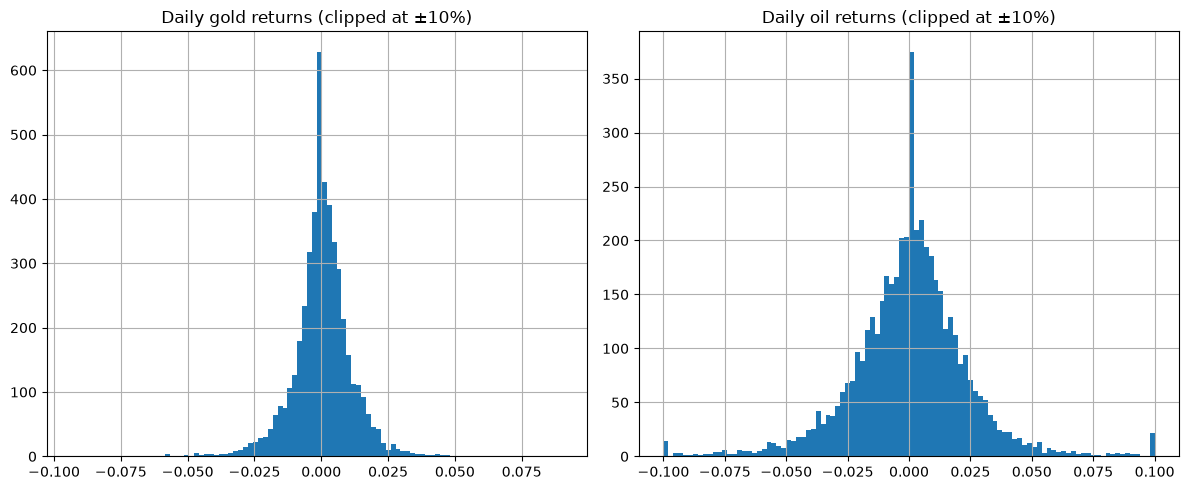

In [37]:
stats = pd.DataFrame({
    "mean (*10^4)": rets.mean() * 1e4,
    "volatility (%)": rets.std() * np.sqrt(260) * 100,
}).round(2)

display(stats.loc[["gold", "oil", "silver", "sp500", "vix"]])


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, a in zip(axes, ["gold", "oil"]):
    rets[a].clip(-0.1, 0.1).hist(bins=100, ax=ax)
    ax.set_title(f"Daily {a} returns (clipped at ±10%)")

plt.tight_layout()
plt.show()

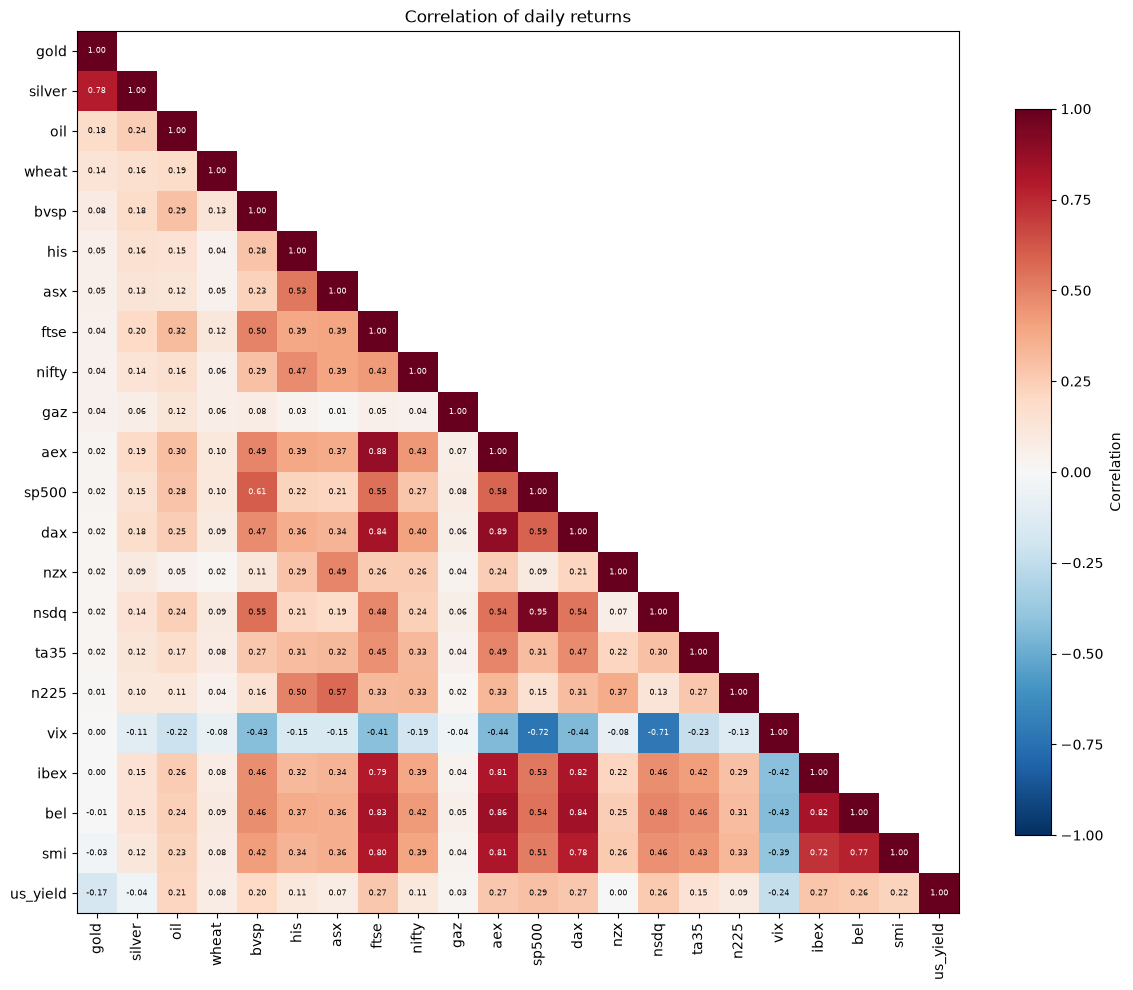

In [38]:
# This part was written by Claude
corr = rets.corr()

order = corr["gold"].sort_values(ascending=False).index
corr = corr.loc[order, order]

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
data = np.ma.masked_where(mask, corr.values)

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(data, cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)

for i in range(len(corr)):
    for j in range(i + 1):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6,
                color="white" if abs(v) > 0.6 else "black")

fig.colorbar(im, ax=ax, shrink=0.8, label="Correlation")
ax.set_title("Correlation of daily returns")

plt.tight_layout()
plt.show()

From these results we can see that over our sample, gold (annualised volatility of about 18%) is much less volatile than oil (about 43%) and slightly less volatile than the S&P 500 (about 20%). After the cleaning of April 2020, the volatility of oil is about half of what naive returns would suggest.

Gold returns have a low contemporaneous correlation with most assets, with the exception of silver (0.78). This was to be anticipated because silver and gold prices are known to be correlated. The US yield is negatively correlated with gold (-0.17): a rise in yields makes holding gold, which pays no interest, less attractive.

Oil, on the other hand, is more linked to equities, with correlations of about 0.3 with the FTSE, the AEX, the Bovespa and the S&P 500. This fits its status as a cyclical commodity, and it is a first reason why gold results may not transfer directly to oil.

In [39]:
# VIX regime used in the paper: dummy = 1 if VIX > 20
print("Share of days with VIX > 20:", round((cleaned_data["vix"] > 20).mean() * 100, 1), "%")

Share of days with VIX > 20: 36.5 %


Cohen & Aiche consider that a VIX above 20 signals extreme market volatility. With about one day out of three above that level, the dummy splits the sample into two regimes of useful size. Note however that it has the **lowest contribution** in the paper's own importance table (Appendix 2), so we should not expect much from it.

## 2.4 Positions of traders: the CFTC Commitments of Traders report

Every week, the CFTC publishes the positions held by large traders on US futures markets. We use the **disaggregated** report (futures only), one file per year from 2011 to 2026 in `data/`. The contracts are selected through their CFTC code, because the name of the WTI contract changes during the sample.

| Group in the report | What it represents |
|---|---|
| Managed Money (`mm`) | Hedge funds and commodity trading advisers: **our main variable** |
| Swap Dealers (`swap`) | Banks hedging swaps, including the flows of commodity **index** investors |
| Producer/Merchant (`prod`) | Physical hedgers |
| Other Reportables (`other`) | Other large traders |
| Non-reportables (`nonrept`) | Small traders |

**Publication date.** The report describes positions on **Tuesday**, but it is published on **Friday at 15:30 New York time**, after the settlement of gold and oil. It can only be used from the following Monday. Some publications are postponed after a public holiday, so we keep a margin of one day: a report becomes usable on the **following Tuesday (+7 days)**.

**The late 2025 backlog.** The US government shutdown interrupted publication. The CFTC cleared its backlog on 29 December 2025 ([CFTC announcements](https://www.cftc.gov/MarketReports/CommitmentsofTraders/HistoricalSpecialAnnouncements/index.htm)). To remain conservative, all reports dated from 30 September to 16 December 2025 are considered usable from 30 December 2025 only.

In [40]:
COT_URL = "https://publicreporting.cftc.gov/resource/72hh-3qpy.json"
COT_CODES = {"088691": "gold", "067651": "oil"}
COT_GROUPS = {
    "mm": ("m_money_positions_long_all", "m_money_positions_short_all"),
    "swap": ("swap_positions_long_all", "swap__positions_short_all"),
    "prod": ("prod_merc_positions_long", "prod_merc_positions_short"),
    "other": ("other_rept_positions_long", "other_rept_positions_short"),
    "nonrept": ("nonrept_positions_long_all", "nonrept_positions_short_all"),
}

def load_cot(start_date: str = "2011-01-01") -> pd.DataFrame:

    columns = [
        "cftc_contract_market_code",
        "report_date_as_yyyy_mm_dd",
        "open_interest_all",
        *[col for pair in COT_GROUPS.values() for col in pair],
    ]

    params = {
        "$select": ",".join(columns),
        "$where": (
            "cftc_contract_market_code IN ('088691', '067651') "
            f"AND report_date_as_yyyy_mm_dd >= '{start_date}'"
        ),
        "$order": "report_date_as_yyyy_mm_dd ASC",
        "$limit": 50000,
    }

    rows = []
    offset = 0

    with requests.Session() as session:
        while True:
            params["$offset"] = offset
            response = session.get(COT_URL, params=params, timeout=60)
            response.raise_for_status()

            batch = response.json()
            if not batch:
                break

            rows.extend(batch)
            offset += len(batch)

            if len(batch) < params["$limit"]:
                break

    cot = pd.DataFrame(rows)

    cot["asset"] = (
        cot["cftc_contract_market_code"]
        .astype(str)
        .str.zfill(6)
        .map(COT_CODES)
    )

    cot = cot.rename(columns={
        "report_date_as_yyyy_mm_dd": "report_date",
        "open_interest_all": "oi",
        **{
            api_col: f"{group}_{position}"
            for group, pair in COT_GROUPS.items()
            for position, api_col in zip(("long", "short"), pair)
        },
    })

    cot["report_date"] = pd.to_datetime(cot["report_date"])

    numeric_cols = [
        "oi",
        *[f"{group}_{position}" for group in COT_GROUPS for position in ("long", "short")],
    ]
    cot[numeric_cols] = cot[numeric_cols].apply(pd.to_numeric, errors="coerce")

    return cot.drop(columns="cftc_contract_market_code").sort_values(
        ["asset", "report_date"]
    ).reset_index(drop=True)


def build_cot_features(cot: pd.DataFrame, asset: str, calendar: pd.DatetimeIndex) -> pd.DataFrame:

    df = cot[cot["asset"] == asset].set_index("report_date").sort_index()

    net = pd.DataFrame({
        f"cot_{group}_net": (df[f"{group}_long"] - df[f"{group}_short"]) / df["oi"]
        for group in COT_GROUPS
    })

    features = net.assign(
        cot_mm_net_chg_1w=net["cot_mm_net"].diff(1),
        cot_mm_net_chg_4w=net["cot_mm_net"].diff(4),
        cot_swap_net_chg_1w=net["cot_swap_net"].diff(1),
        cot_mm_net_z52=(net["cot_mm_net"] - net["cot_mm_net"].rolling(52).mean()) / net["cot_mm_net"].rolling(52).std(),
        cot_oi_chg_1w=df["oi"].pct_change(fill_method=None),
    )

    # Dating the data when it can be used, not when positions were observed
    usable = pd.Series(features.index + pd.Timedelta(days=7), index=features.index)
    usable[(features.index >= "2025-09-30") & (features.index <= "2025-12-16")] = pd.Timestamp("2025-12-30")
    features = features.groupby(usable.values).last()

    return features.reindex(calendar.union(features.index)).ffill().reindex(calendar)

       count        min        max
asset                             
gold     827 2011-01-04 2026-11-03
oil      827 2011-01-04 2026-11-03


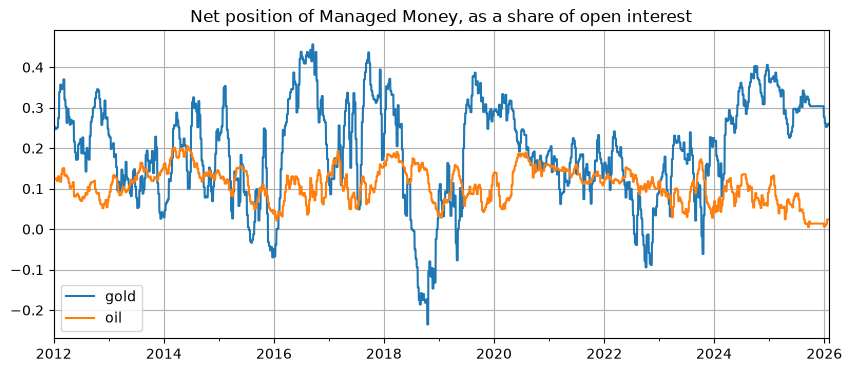

In [41]:
cot = load_cot()
print(cot.groupby("asset")["report_date"].agg(["count", "min", "max"]))

cot_plot = {
    a: build_cot_features(cot, a, cleaned_data.index)["cot_mm_net"].loc["2012":]
    for a in ["gold", "oil"]
}
pd.DataFrame(cot_plot).plot(figsize=(10, 4), grid=True, title="Net position of Managed Money, as a share of open interest")
plt.show()

Each contract has 823 weekly reports. Managed Money is on average net long, by about 15% of open interest in gold and 8% in oil. Its position varies much more on gold, from -15% to +34% of open interest, against -1% to +16% on oil. So there is real variation to exploit, particularly in gold. The flat part at the end of 2025 is the effect of our conservative treatment of the publication backlog.

# 3. Analytics and learning strategies

## 3.1 Features and target

For each asset, daily **returns** are computed, then **lags 1 to 10** of every asset (including the target asset itself) are created, together with **moving averages (orders 2 to 10) of the target returns** and the **VIX dummy** (VIX > 20), as in Cohen & Aiche (2023).

`lag_1` is the **most recent return available** when the decision is made (see `info_lag`). The target is the next-day return of gold (or oil). The moving average dated *t* includes *r(t)*. That is legitimate because the target is *r(t+1)*. Section 4.1 shows what happens otherwise.

In [42]:
def build_features(prices: pd.DataFrame, lag_order: int = 10, target_col: str = "oil", timing: str = "async"):

    ret = compute_returns(prices)
    return_cols = ret.columns.tolist()

    # compute lags up to order 10 of all the columns
    lag_features = {
        f"{col}_lag_{i}": ret[col].shift(i - 1 + info_lag(col, target_col, timing))
        for col in return_cols
        for i in range(1, lag_order + 1)
    }

    # moving averages on the target_col up to order 10. we exclude order 1 since it is equivalent to just seeing lag 1. It would introduce a duplicate column
    target_lag = info_lag(target_col, target_col, timing)
    ma_features = {
        f"{target_col}_ma{i}": ret[target_col].shift(target_lag).rolling(window=i, min_periods=i).mean()
        for i in range(2, lag_order + 1)
    }

    # the VIX dummy follows the same availability rule as the VIX itself
    vix_dummy = (prices["vix"].shift(info_lag("vix", target_col, timing)) > 20).astype("int8").rename("vix_dummy")

    features = pd.concat([pd.DataFrame(lag_features), pd.DataFrame(ma_features), vix_dummy.reindex(ret.index)], axis=1).dropna()
    target = ret[target_col].shift(-1).reindex(features.index).rename("target")
    ret_target = ret[target_col]

    # Verifications
    assert len(features.index) == features.index.nunique()
    assert features.isna().any().sum() == 0
    assert np.isfinite(features).all().all()
    assert target.iloc[:-1].notna().all()

    return features, target, ret_target

In [43]:
features_oil, target_oil, ret_oil = build_features(cleaned_data, lag_order=10, target_col="oil")
features_gold, target_gold, ret_gold = build_features(cleaned_data, lag_order=10, target_col="gold")

print("Number of features:", features_gold.shape[1], "(22 series x 10 lags, 9 moving averages, 1 VIX dummy)")

Number of features: 230 (22 series x 10 lags, 9 moving averages, 1 VIX dummy)


## 3.2 Algorithms

**Decision tree (regression tree).** Recursively splits the feature space into regions and predicts the mean target in each leaf, minimising the sum of squared errors $\sum_{c}\sum_{i\in c}(y_i-m_c)^2$. Easy to interpret, but high variance.

**Random forest.** Averages $B$ trees, each grown on a bootstrap sample with a random subset of features at each split: $\hat f(x)=\frac1B\sum_{b=1}^B T_b(x)$. Averaging decorrelated trees lowers variance.

**Gradient boosting.** Builds trees sequentially, each fitted to the negative gradient (the residuals, for squared loss) of the current ensemble: $f_m(x)=f_{m-1}(x)+\nu\, T_m(x)$ with learning rate $\nu$. Shallow trees plus a small learning rate act as regularisation.

**XGBoost.** A regularised version of gradient boosting. It adds L1 and L2 penalties on the leaf weights to the objective and uses a second-order approximation of the loss. It is one of the two best models of the paper.

**Feature selection.**

(i) *Permutation importance* of the random forest, averaged over time-series folds, keeping the top 25 features;

(ii) *LASSO persistence*: a `LassoCV` is fitted on each time-series fold and features are ranked by how often their coefficient is non-zero.

**From a forecast to a position.** We follow the timing pipeline of `skfin`: a regressor predicts the return, then `TimingMeanVariance` converts the prediction into a position,

$$h_t = \frac{1}{\sigma}\,\mathrm{clip}\left(\frac{\hat r_{t+1}}{\sigma}, -0.25, 0.25\right),$$

where $\sigma$ is the volatility of the target **on the training window only**. The clip limits the leverage. The strategy earns $h_t \, r_{t+1}$.

**skfin code.** All the functions below come from https://github.com/schampon/skfin (commit `63be893`) and are **copied without any modification**. `skfin` connects a regressor to `TimingMeanVariance` through a `transform` method, added by its `_add_transform` decorator. We apply this same decorator to the tree models.

**`skfin.metrics`**

In [44]:
def _test_monthly(df: pd.Series) -> bool:
    """Check if the series has monthly frequency."""
    return int(len(df) / len(df.asfreq("ME"))) == 1


def _test_bday(df: pd.Series) -> bool:
    """Check if the series has business-day frequency."""
    return int(len(df) / len(df.asfreq("B"))) == 1


def _test_day(df: pd.Series) -> bool:
    """Check if the series has calendar-day frequency."""
    return int(len(df) / len(df.asfreq("D"))) == 1


def sharpe_ratio(
    df: pd.Series,
    num_period_per_year: int | None = None,
    remove_zeros: bool = True,
) -> float:
    """Compute annualized Sharpe ratio.

    Args:
        df: PnL or returns series with a DatetimeIndex.
        num_period_per_year: Annualization factor. Auto-detected from index if None.
        remove_zeros: Replace zeros with NaN before computing (avoids deflating vol).

    Returns:
        Annualized Sharpe ratio, or NaN if frequency cannot be detected.
    """
    if num_period_per_year is None:
        if _test_monthly(df):
            num_period_per_year = 12
        if _test_bday(df):
            num_period_per_year = 260
        if _test_day(df):
            num_period_per_year = 365
        if num_period_per_year is None:
            return np.nan
    if remove_zeros:
        df = df.replace(0, np.nan)
    return df.mean() / df.std() * np.sqrt(num_period_per_year)


def drawdown(
    x: pd.Series,
    return_in_risk_unit: bool = True,
    window: int = 36,
    num_period_per_year: int = 12,
) -> pd.Series:
    """Compute drawdown from peak cumulative PnL.

    Args:
        x: PnL or returns series.
        return_in_risk_unit: Normalize by rolling volatility for cross-strategy comparison.
        window: Rolling window for volatility estimate (in periods).
        num_period_per_year: Annualization factor for the volatility normalization.

    Returns:
        Drawdown series (non-positive values; 0 at peaks).
    """
    dd = x.cumsum().sub(x.cumsum().cummax())
    if return_in_risk_unit:
        return dd.div(x.rolling(window).std().mul(np.sqrt(num_period_per_year)))
    return dd

**`skfin.estimators.mean_variance`**

In [45]:
def compute_batch_holdings(
    pred: np.ndarray | pd.Series | pd.DataFrame,
    V: np.ndarray,
    A: np.ndarray | None = None,
    risk_target: float | None = None,
) -> np.ndarray:
    """Compute Markowitz portfolio holdings from predictions and covariance.

    Args:
        pred: Return predictions, shape (N,) or (N, K) or (K, N).
        V: Covariance matrix, shape (N, N).
        A: Constraint matrix. None for unconstrained.
        risk_target: Target portfolio volatility. None disables scaling.

    Returns:
        Holdings array, shape (K, N).
    """
    N, _ = V.shape
    if isinstance(pred, (pd.Series, pd.DataFrame)):
        pred = pred.values
    if pred.ndim == 1:
        pred = pred[:, np.newaxis]
    elif pred.shape[1] == N:
        pred = pred.T

    invV = np.linalg.inv(V)
    if A is None:
        M = invV
    else:
        U = invV.dot(A)
        if A.ndim == 1:
            M = invV - np.outer(U, U.T) / U.dot(A)
        else:
            M = invV - U.dot(np.linalg.inv(U.T.dot(A)).dot(U.T))
    h = M.dot(pred)
    if risk_target is not None:
        h = risk_target * h / np.sqrt(np.diag(h.T.dot(V.dot(h))))
    return h.T


@dataclass
class MeanVariance(BaseEstimator):
    """Mean-variance optimizer that computes portfolio holdings from predictions and covariance."""

    transform_V: Callable = field(default=lambda x: np.cov(x.T))
    A: np.ndarray | str | None = "cash-neutral"
    risk_target: float = 1.0

    def __post_init__(self):
        self.holdings_kwargs = {"risk_target": self.risk_target}

    @staticmethod
    def compute_batch_holdings(
        pred: np.ndarray,
        V: np.ndarray,
        A: np.ndarray | None,
        risk_target: float | None,
        **kwargs,
    ) -> np.ndarray:
        """Compute portfolio holdings in batch."""
        return compute_batch_holdings(pred=pred, V=V, A=A, risk_target=risk_target, **kwargs)

    def fit(self, X, y=None):
        self.V_ = self.transform_V(y)
        return self

    def predict(self, X, **kwargs):
        if isinstance(X, (pd.Series, pd.DataFrame)):
            X = X.values
        n_assets = X.shape[1] if X.ndim > 1 else X.shape[0]
        if isinstance(self.A, str) and self.A == "cash-neutral":
            A = np.ones((n_assets, 1))
        else:
            A = self.A
        kwargs = {**kwargs, **self.holdings_kwargs}
        h = self.compute_batch_holdings(pred=X, V=self.V_, A=A, **kwargs)
        return h

    def transform(self, X, **kwargs):
        """Alias for predict (enables sklearn pipeline use)."""
        return self.predict(X, **kwargs)

    def score(self, X, y):
        """Compute Sharpe ratio of the portfolio PnL."""
        return sharpe_ratio(np.sum(X * y, axis=1))


class TimingMeanVariance(BaseEstimator):
    """Single-asset timing estimator that scales positions by inverse volatility."""

    def __init__(
        self,
        transform_V: Callable | None = None,
        a_min: float | None = None,
        a_max: float | None = None,
    ):
        if transform_V is None:
            self.transform_V = lambda x: np.var(x)
        else:
            self.transform_V = transform_V
        self.a_min = a_min
        self.a_max = a_max

    def fit(self, X, y=None):
        self.V_ = self.transform_V(y)
        return self

    def predict(self, X):
        if self.a_min is None and self.a_max is None:
            h = X / self.V_
        else:
            h = np.clip(
                X / np.sqrt(self.V_), a_min=self.a_min, a_max=self.a_max
            ) / np.sqrt(self.V_)
        return h

    def transform(self, X):
        """Alias for predict (enables sklearn pipeline use)."""
        return self.predict(X)

**`skfin.backtesting`**

In [46]:
def compute_pnl(
    h: pd.DataFrame | pd.Series,
    ret: pd.DataFrame | pd.Series,
    pred_lag: int,
) -> pd.Series:
    """Compute PnL from holdings and returns.

    Args:
        h: Holdings at each time step.
        ret: Asset returns.
        pred_lag: Number of periods to lag holdings (avoids lookahead).

    Returns:
        PnL series (summed across assets if multi-asset).
    """
    pnl = h.shift(pred_lag).mul(ret)
    if isinstance(h, pd.DataFrame):
        pnl = pnl.sum(axis=1)
    return pnl


def fit_predict(
    estimator: BaseEstimator,
    X: np.ndarray,
    y: np.ndarray,
    train: np.ndarray,
    test: np.ndarray,
    return_estimator: bool = True,
) -> tuple:
    """Fit estimator on train split and predict on test split.

    Args:
        estimator: sklearn-compatible estimator.
        X: Feature matrix.
        y: Target matrix.
        train: Train indices.
        test: Test indices.
        return_estimator: If True, return (predictions, fitted_estimator).

    Returns:
        Predictions, or tuple of (predictions, estimator).
    """
    X_train, y_train = _safe_split(estimator, X, y, train)
    X_test, _ = _safe_split(estimator, X, y, test, train)
    estimator.fit(X_train, y_train)
    if return_estimator:
        return estimator.predict(X_test), estimator
    else:
        return estimator.predict(X_test)


@dataclass
class Backtester:
    """Walk-forward backtester using sklearn TimeSeriesSplit."""

    estimator: BaseEstimator = None
    max_train_size: int = 36
    test_size: int = 1
    pred_lag: int = 1
    start_date: str = "1945-01-01"
    end_date: str | None = None
    name: str | None = None

    def __post_init__(self):
        if self.estimator is None:
            self.estimator = MeanVariance()

    def compute_holdings(
        self,
        X: pd.DataFrame,
        y: pd.DataFrame | pd.Series,
        pre_dispatch: str = "2*n_jobs",
        n_jobs: int = 1,
    ):
        """Compute holdings via walk-forward cross-validation.

        Args:
            X: Feature matrix with DatetimeIndex.
            y: Target matrix (returns used for covariance estimation).
            pre_dispatch: joblib pre_dispatch parameter.
            n_jobs: Number of parallel jobs.

        Returns:
            self (with h_, estimators_, cv_ fitted attributes).
        """
        X = X.loc[:self.end_date]
        cv = TimeSeriesSplit(
            max_train_size=self.max_train_size,
            test_size=self.test_size,
            n_splits=1 + len(X.loc[self.start_date:]) // self.test_size,
        )
        parallel = Parallel(n_jobs=n_jobs, pre_dispatch=pre_dispatch)
        res = parallel(
            delayed(fit_predict)(
                clone(self.estimator), X.values, y.values, train, test, True
            )
            for train, test in cv.split(X)
        )
        y_pred, estimators = zip(*res)
        idx = X.index[np.concatenate([test for _, test in cv.split(X)])]
        if isinstance(y, pd.DataFrame):
            cols = y.columns
            h = pd.DataFrame(np.concatenate(y_pred), index=idx, columns=cols)
        elif isinstance(y, pd.Series):
            h = pd.Series(np.concatenate(y_pred), index=idx)
        else:
            h = None
        self.h_ = h
        self.estimators_ = estimators
        self.cv_ = cv
        return self

    def compute_pnl(self, ret: pd.DataFrame | pd.Series):
        """Compute PnL from fitted holdings and returns.

        Args:
            ret: Asset returns (same index/columns as y).

        Returns:
            self (with pnl_ fitted attribute).
        """
        pnl = compute_pnl(self.h_, ret, self.pred_lag)
        self.pnl_ = pnl.loc[self.start_date:self.end_date]
        if self.name:
            self.pnl_ = self.pnl_.rename(self.name)
        return self

    def train(
        self,
        X: pd.DataFrame,
        y: pd.DataFrame | pd.Series,
        ret: pd.DataFrame | pd.Series,
    ) -> pd.Series:
        """Run full backtest: compute holdings then PnL.

        Args:
            X: Feature matrix.
            y: Target matrix for fitting.
            ret: Returns for PnL computation.

        Returns:
            PnL series.
        """
        self.compute_holdings(X, y)
        self.compute_pnl(ret)
        return self.pnl_

**`skfin.plot`**

In [47]:
def set_axis(
    ax: plt.Axes | None = None,
    figsize: tuple = (8, 5),
    title: str | None = None,
    fig: plt.Figure | None = None,
) -> tuple[plt.Figure, plt.Axes]:
    """Create or reuse a matplotlib figure and axes pair.

    Args:
        ax: Existing axes to reuse. If None, creates a new figure.
        figsize: Figure size as (width, height) in inches.
        title: Optional title for the axes.
        fig: Existing figure to associate with the axes.

    Returns:
        Tuple of (figure, axes).
    """
    if ax is None:
        fig, ax = plt.subplots(1, 1, figsize=figsize)
    else:
        fig = fig or ax.get_figure()
    if title is not None:
        ax.set_title(title)
    return fig, ax


def line(
    df: pd.DataFrame | pd.Series | dict | list,
    sort: bool = True,
    figsize: tuple = (8, 5),
    ax: plt.Axes | None = None,
    title: str = "",
    cumsum: bool = False,
    loc: str = "center left",
    bbox_to_anchor: tuple | None = (1, 0.5),
    legend_sharpe_ratio: bool | None = None,
    legend: bool = True,
    yscale: str | None = None,
    start_date: str | None = None,
):
    """Plot one or more time series as lines.

    Args:
        df: Data to plot. Accepts DataFrame, Series, dict, or list of Series.
        sort: Sort columns by final value (highest on top).
        figsize: Figure size as (width, height) in inches.
        ax: Existing axes to plot on.
        title: Plot title.
        cumsum: Cumulate the series before plotting.
        loc: Legend location string.
        bbox_to_anchor: Legend anchor point.
        legend_sharpe_ratio: Append Sharpe ratio to legend labels. Auto-enabled with cumsum.
        legend: Whether to show the legend.
        yscale: Y-axis scale (e.g. "log").
        start_date: Trim data before this date.
    """
    df = df.copy() if isinstance(df, (pd.DataFrame, pd.Series)) else df
    if loc == "best":
        bbox_to_anchor = None
    if isinstance(df, (dict, list)):
        df = pd.concat(df, axis=1)
    if isinstance(df, pd.Series):
        df = df.to_frame()
    if start_date is not None:
        df = df[start_date:]
    if cumsum and legend_sharpe_ratio is None:
        legend_sharpe_ratio = True
    if legend_sharpe_ratio:
        df.columns = [f"{c}: sr={sharpe_ratio(df[c]): 3.2f}" for c in df.columns]
    if cumsum:
        df = df.cumsum()
    if sort:
        df = df.loc[:, lambda x: x.iloc[-1].sort_values(ascending=False).index]
    if ax is None:
        fig, ax = set_axis(ax=ax, figsize=figsize)
    ax.set_axisbelow(True)
    ax.grid(True, linestyle="--", alpha=0.5)
    if title != "":
        ax.set_title(title)
    ax.plot(df.index, df.values)
    if legend:
        ax.legend(df.columns, loc=loc, bbox_to_anchor=bbox_to_anchor)
    if yscale == "log":
        ax.set_yscale("log")

**`skfin.estimators.linear`**, applied to the tree models of this project

In [48]:
def _add_transform(cls):
    """Decorator that aliases transform to predict."""
    def transform(self, X):
        return self.predict(X)
    cls.transform = transform
    return cls


@_add_transform
class DecisionTreeRegressor(_DecisionTreeRegressor):
    """DecisionTreeRegressor with transform() for sklearn pipeline use."""
    pass


@_add_transform
class RandomForestRegressor(_RandomForestRegressor):
    """RandomForestRegressor with transform() for sklearn pipeline use."""
    pass


@_add_transform
class GradientBoostingRegressor(_GradientBoostingRegressor):
    """GradientBoostingRegressor with transform() for sklearn pipeline use."""
    pass


@_add_transform
class XGBRegressor(_XGBRegressor):
    """XGBRegressor with transform() for sklearn pipeline use."""
    pass

## 3.3 Data partitioning: training, validation and test

| Period | Use |
|---|---|
| start → **2020-12-31** | **Tuning set.** Hyper-parameter search and feature selection, with time-series cross-validation |
| **2021-01-01** → 2026-01-30 | **Out-of-sample test.** Walk-forward. Nothing from this period is used for tuning. |

Inside the test period, each model is re-trained every 40 days on a rolling window of past data. No shuffling is used anywhere, and every validation window lies strictly after its training window.

The replication of the paper (section 4.1) is the exception. It uses the paper's own single split, on 26 September 2019.

In [49]:
def prepare_tuning_data(features: pd.DataFrame, target: pd.Series, tuning_end_date: str = "2020-12-31"):

    X_tune = features.loc[:tuning_end_date]
    y_tune = target.reindex(X_tune.index)

    # The label of the last day is the first return of the test period
    return X_tune.iloc[:-1], y_tune.iloc[:-1]

## 3.4 Parameter selection and optimisation

Hyper-parameters are chosen by **randomised search** over the grids below, with `TimeSeriesSplit` cross-validation and **RMSE** as the criterion.

- The **length of the training window** is treated as a hyper-parameter, and validation uses the same rolling window as the backtest.
- The 10 validation folds of 120 days cover about 2016 to 2020, so the choice does not depend on one single market regime.
- The best model of each asset is the one with the lowest validation RMSE. It is chosen **before** looking at the test period.

The best configuration of each model is then re-used, unchanged, in the walk-forward backtest.

In [ ]:
TRAIN_WINDOWS = (120,) # For the sake of speed, we just use one window. We can use others too.
N_ITER = 15

models_and_params = {
    "Decision Tree": (
        DecisionTreeRegressor(random_state=RNDM_SEED),
        {
            "max_depth": [1, 2, 3, 5],
            "min_samples_leaf": [5, 10, 20, 30],
            "max_features": [1.0, 0.5, "sqrt"],
        },
    ),
    "Random Forest": (
        RandomForestRegressor(n_estimators=200, random_state=RNDM_SEED, n_jobs=1),
        {
            "max_depth": [2, 3, 5, 8],
            "min_samples_leaf": [5, 10, 20, 30],
            "max_features": [0.5, 0.2, "sqrt"],
        },
    ),
    "Gradient Boosting": (
        GradientBoostingRegressor(random_state=RNDM_SEED),
        {
            "n_estimators": [50, 100, 200, 300],
            "learning_rate": [0.01, 0.03, 0.05, 0.1],
            "max_depth": [1, 2, 3],
            "min_samples_leaf": [5, 10, 20, 30],
            "subsample": [0.5, 0.8, 1.0],
        },
    ),
    "XGBoost": (
        XGBRegressor(random_state=RNDM_SEED, n_jobs=1),
        {
            "n_estimators": [50, 100, 200, 300],
            "learning_rate": [0.01, 0.03, 0.05, 0.1],
            "max_depth": [1, 2, 3],
            "subsample": [0.5, 0.8, 1.0],
            "colsample_bytree": [0.2, 0.5, 1.0],
            "reg_alpha": [0, 1e-3, 1e-2],
            "reg_lambda": [1, 10, 100],
        },
    ),
}

TUNING_END_DATE = "2020-12-31"
PREDICTION_START_DATE = "2021-01-01"

X_tune_oil, y_tune_oil = prepare_tuning_data(features=features_oil, target=target_oil, tuning_end_date=TUNING_END_DATE)
X_tune_gold, y_tune_gold = prepare_tuning_data(features=features_gold, target=target_gold, tuning_end_date=TUNING_END_DATE)

In [ ]:
def hyperparameter_optimization(features: pd.DataFrame,
                                target: pd.Series,
                                models_and_params: dict,
                                train_windows: tuple = TRAIN_WINDOWS,
                                n_splits: int = 10,
                                test_size: int = 120,
                                n_iter: int = N_ITER):

    best_models, best_windows, summary = {}, {}, {}

    for name, (model, param_grid) in models_and_params.items():
        best_rmse = np.inf

        for window in train_windows:
            cv = TimeSeriesSplit(n_splits=n_splits, max_train_size=window, test_size=test_size)

            search = RandomizedSearchCV(
                estimator=model,
                param_distributions=param_grid,
                n_iter=n_iter,
                scoring="neg_root_mean_squared_error",
                cv=cv,
                random_state=RNDM_SEED,
                n_jobs=-1,
                refit=False,
                error_score="raise",
            )
            search.fit(features, target)

            if -search.best_score_ < best_rmse:
                best_rmse = -search.best_score_
                best_windows[name] = window
                best_models[name] = clone(model).set_params(**search.best_params_)
                summary[name] = {"CV RMSE": best_rmse, "train window": window, **search.best_params_}

    # Reference: always predicting a zero return, on the same validation folds
    folds = TimeSeriesSplit(n_splits=n_splits, test_size=test_size).split(features)
    zero_rmse = np.mean([np.sqrt((target.iloc[test] ** 2).mean()) for _, test in folds])

    table = pd.DataFrame(summary).T
    print(f"RMSE of a zero forecast on the same folds: {zero_rmse:.6f}")
    display(table.astype(object).where(table.notna(), "").round(6))

    return best_models, best_windows, table["CV RMSE"].astype(float).idxmin()

In [ ]:
print("OIL")
best_models_oil, best_windows_oil, best_name_oil = hyperparameter_optimization(X_tune_oil, y_tune_oil, models_and_params)
print("GOLD")
best_models_gold, best_windows_gold, best_name_gold = hyperparameter_optimization(X_tune_gold, y_tune_gold, models_and_params)
print("Model selected before the test period. Gold:", best_name_gold, "| Oil:", best_name_oil)

OIL


TypeError: 'int' object is not iterable

**What the tuning tells us.** Validation errors are nearly the same as those of a zero forecast: at best slightly lower for gold (0.008400 against 0.008415), never lower for oil (0.026104 against 0.026099). The selected configurations are mostly very constrained, with stumps or shallow trees, small learning rates and strong penalties. This is what we should expect when the signal is weak: to minimise RMSE, the best thing a model can do is predict almost nothing.

It also has a consequence: the differences between models are too small for validation to separate them reliably. The Random Forest is selected for both assets, but with such small gaps we report the four models in all our results, and we keep in mind which one was chosen *in advance*.

## 3.5 Implementation of the backtest and performance metrics

`run_backtest` only connects existing pieces: it builds the `skfin` pipeline, runs `Backtester`, and also recovers the raw forecasts, which the forecast metrics need.

**Forecast metrics.** $R^2_{0}=1-\sum(r-\hat r)^2/\sum r^2$ compares the model to a **zero forecast**, and $R^2_{hist}$ compares it to the **historical mean**. A negative value means the model is worse than this naive forecast. Beating zero can simply reflect the upward drift of an asset, so beating the historical mean is the more demanding comparison.

**Trading metrics.**
- *Cumulated PnL* and *Sharpe ratio*, computed by `skfin`. No transaction costs are included.
- *Maximum drawdown*, computed by `skfin` and expressed in units of volatility.
- *Buy & hold*: the benchmark, because timing an asset that rose is easy if the model is simply long most of the time.

`TimingMeanVariance` implies a high leverage, so PnL levels are not directly comparable across strategies. The PnL curves and the cumulated PnL in the tables are therefore rescaled to the same volatility of 10% per year. This rescaling does not change any Sharpe ratio.

In [ ]:
NUM_PERIOD_PER_YEAR = 260 # The common calendar has about 260 rows per year, the frequency detected by sharpe_ratio

def run_backtest(features, target, ret, model, train_window, start_date=PREDICTION_START_DATE, test_size=40, name=None):

    estimator = make_pipeline(clone(model), TimingMeanVariance(a_min=-0.25, a_max=0.25))
    bt = Backtester(
        estimator=estimator,
        max_train_size=train_window,
        test_size=test_size,
        pred_lag=1,
        start_date=start_date,
        name=name,
    )
    bt.compute_holdings(features, target, n_jobs=-1).compute_pnl(ret)

    # The fitted pipelines also give the forecast before it is converted into a position
    tests = [test for _, test in bt.cv_.split(features)]
    forecasts = [m[:-1].predict(features.values[test]) for test, m in zip(tests, bt.estimators_)]
    idx = features.index[np.concatenate(tests)]
    bt.predictions_ = pd.Series(np.concatenate(forecasts), index=idx).loc[start_date:]
    bt.pnl_ = bt.pnl_.dropna()

    return bt

def forecast_metrics(bt, target, ret) -> dict:

    pred = bt.predictions_
    actual = target.reindex(pred.index).dropna()
    pred = pred.loc[actual.index]
    hist_mean = ret.expanding().mean().reindex(actual.index)

    return {
        "R2 vs zero": 1 - ((actual - pred) ** 2).sum() / (actual ** 2).sum(),
        "R2 vs hist. mean": 1 - ((actual - pred) ** 2).sum() / ((actual - hist_mean) ** 2).sum(),
    }

def rescale(pnl: pd.Series, vol: float = 0.10) -> pd.Series:
    return pnl * vol / (pnl.std() * np.sqrt(NUM_PERIOD_PER_YEAR))

def trading_metrics(pnl: pd.Series) -> dict:

    return {
        "Cumulated PnL (10% vol)": rescale(pnl).sum(),
        "Sharpe": sharpe_ratio(pnl),
        "Max drawdown": drawdown(pnl, window=36, num_period_per_year=NUM_PERIOD_PER_YEAR).min(),
    }

def display_results(features, target, ret, best_models, best_windows, start_date=PREDICTION_START_DATE, asset="Oil"):

    backtests = {
        name: run_backtest(features, target, ret, model, best_windows[name], start_date=start_date, name=name)
        for name, model in best_models.items()
    }
    pnl = pd.DataFrame({name: bt.pnl_ for name, bt in backtests.items()})
    series = {**pnl.to_dict("series"), "Buy & hold": ret.reindex(pnl.index)}

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    line({c: rescale(s) for c, s in series.items()},
         cumsum=True, title=f"Cumulated PnL for {asset} (10% annual volatility)", ax=axes[0], loc="best")
    line({c: drawdown(s, window=36, num_period_per_year=NUM_PERIOD_PER_YEAR) for c, s in series.items()},
         title=f"Drawdown for {asset} (risk units)", ax=axes[1], loc="best", legend_sharpe_ratio=False)
    plt.tight_layout()
    plt.show()

    print("Forecast performance")
    display(pd.DataFrame({n: forecast_metrics(bt, target, ret) for n, bt in backtests.items()}).T.round(4))

    print("Trading performance, without transaction costs")
    display(pd.DataFrame({n: trading_metrics(s) for n, s in series.items()}).T.round(2))

    print("Sharpe ratio per year")
    display(pd.DataFrame({
        n: s.groupby(s.index.year).apply(lambda x: x.mean() / x.std() * np.sqrt(NUM_PERIOD_PER_YEAR))
        for n, s in series.items()
    }).T.round(2))

    return backtests

**Feature-selection functions**

In [ ]:
def features_selector_rf(model, X_tune: pd.DataFrame, y_tune: pd.Series, n_features: int = 25, show_features: bool = False):

    cv = TimeSeriesSplit(n_splits=5)
    fold_importances = []

    for train_idx, val_idx in cv.split(X_tune):
        selector = clone(model)
        selector.fit(X_tune.iloc[train_idx], y_tune.iloc[train_idx])

        importance = permutation_importance(
            selector,
            X_tune.iloc[val_idx],
            y_tune.iloc[val_idx],
            scoring="neg_root_mean_squared_error",
            n_repeats=5,
            random_state=RNDM_SEED,
            n_jobs=-1,
        )

        fold_importances.append(
            pd.Series(importance.importances_mean, index=X_tune.columns)
        )

    importance_scores = (
        pd.concat(fold_importances, axis=1)
        .mean(axis=1)
        .sort_values(ascending=False)
    )

    if show_features:
        display(importance_scores.head(n_features).to_frame("Importance"))

    return importance_scores.head(n_features).index.to_list()

In [ ]:
def features_selector_lasso(
    X_tune: pd.DataFrame,
    y_tune: pd.Series,
    show_features: bool = False,
    selection_threshold: float = 0.0
):
    cv = TimeSeriesSplit(n_splits=5)
    selection_counts = pd.Series(0, index=X_tune.columns, dtype=int)

    for train_idx, _ in cv.split(X_tune):
        X_train = X_tune.iloc[train_idx]
        y_train = y_tune.iloc[train_idx]

        selector = make_pipeline(
            StandardScaler(),
            LassoCV(cv=TimeSeriesSplit(n_splits=5), max_iter=20_000, random_state=RNDM_SEED),
        )

        selector.fit(X_train, y_train)

        coefficients = selector.named_steps["lassocv"].coef_
        selected = np.abs(coefficients) > selection_threshold

        selection_counts.loc[X_tune.columns[selected]] += 1

    persistence = (selection_counts / cv.n_splits).sort_values(ascending=False)

    if show_features:
        display(
            persistence.head(50)
            .rename("Selection frequency")
            .to_frame()
        )

    return persistence[persistence > 0].index.to_list()

# 4. Empirical results: baseline and robustness

## 4.1 H1: replicating the paper

**H1:** *the predictors selected in the paper, rebuilt from open data and fed to the most performant model, deliver an out-of-sample performance comparable to the one reported in the paper.*

**Protocol.** We follow the paper as closely as its description allows: sample from February 2011 to February 2023, single split on 26 September 2019, target $r(t)$, and predictors from its Appendix 1. The hyper-parameters reported in the paper are used where available: 17 leaves for the tree, 463 trees for the forest, 1100 trees of depth 15 for GBRT. The paper does not report the others, such as the learning rate, so we make assumptions about them. The paper's metric is the relative error $RSE = MSE / Var(r)$, equal to $1 - R^2$.

**What is the "most performant model"?** The paper presents XGBoost as the most accurate, but its own numbers give the same MSE for both and a lower RSE for GBRT (0.166 vs 0.193). We report both.

**A suspicious detail.** An RSE of 0.166 means $R^2 = 0.83$ on daily gold returns, which would be an extraordinary result. The three most important variables of the paper are `Gold_MA_3`, `l1_GOLD` and `l2_GOLD`. Yet if the 3-day moving average **includes the current day**, the target can be recovered exactly from them:

$$r(t) = 3 \times MA_3(t) - r(t-1) - r(t-2).$$

The paper does not say how its moving averages are computed, so we estimate each model **twice**: with moving averages of past returns only (the correct design) and with moving averages that contain the current day.

In [ ]:
PAPER_LAGS = {
    "target": [1, 2, 3, 4, 5, 6, 7, 8, 9],
    "sp500": [1, 2, 7],
    "ta35": [1, 2],
    "ibex": [1, 9],
    "aex": [1, 4, 5, 6, 7, 8, 10],
    "bel": [1, 4, 5, 6, 7, 8, 9],
    "asx": [1, 8],
    "vix": [1],
    "us_yield": [1, 3],
    "japan_yield": [1],
    "nsdq": [2, 10],
    "nifty": [2, 4, 6, 7, 8],
    "n225": [2, 3, 4, 5, 6, 7, 8, 9],
    "bvsp": [3],
    "smi": [4, 5],
    "his": [4, 5],
    "gaz": [6, 9],
    "ftse": [6, 7, 9],
    "silver": [8, 9, 10],
    "wheat": [9],
    "dax": [10],
    "nzx": [10],
}
PAPER_MA = [3, 5, 10]
PAPER_VIX_DUMMY_LAGS = [1, 3, 10]
PAPER_RSE = {"Decision Tree": 0.6401, "Random Forest": 0.43635, "Gradient Boosting": 0.16593, "XGBoost": 0.1928}
PAPER_START, PAPER_END, PAPER_SPLIT = "2011-02-01", "2023-02-28", "2019-09-26"

paper_models = {
    "Decision Tree": DecisionTreeRegressor(max_leaf_nodes=17, random_state=RNDM_SEED),
    "Random Forest": RandomForestRegressor(n_estimators=463, max_features=1 / 3, random_state=RNDM_SEED, n_jobs=1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=1100, max_depth=15, learning_rate=0.01, subsample=0.5,
                                                   min_samples_leaf=10, random_state=RNDM_SEED),
    "XGBoost": XGBRegressor(n_estimators=1000, max_depth=6, learning_rate=0.01, subsample=0.8, colsample_bytree=0.8,
                            random_state=RNDM_SEED, n_jobs=1),
}

def build_paper_design(prices: pd.DataFrame, target_col: str, ma_contains_target: bool) -> pd.DataFrame:

    ret = compute_returns(prices)
    columns = {}

    for col, lags in PAPER_LAGS.items():
        source = target_col if col == "target" else col
        for i in lags:
            columns[f"{source}_l{i}"] = ret[source].shift(i)

    base = ret[target_col] if ma_contains_target else ret[target_col].shift(1)
    for i in PAPER_MA:
        columns[f"{target_col}_ma{i}"] = base.rolling(i).mean()

    columns["vix"] = prices["vix"].reindex(ret.index)
    design = pd.DataFrame(columns)
    for i in PAPER_VIX_DUMMY_LAGS:
        design[f"vix_dummy_l{i}"] = (design["vix"].shift(i) > 20).astype("int8")
    design = design.drop(columns="vix")

    design["y"] = ret[target_col]
    return design.dropna().loc[PAPER_START:PAPER_END]

def replicate_one(name, model, prices, target_col, ma_contains_target):

    design = build_paper_design(prices, target_col, ma_contains_target)
    train, test = design.loc[:PAPER_SPLIT], design.loc[PAPER_SPLIT:].iloc[1:]

    fitted = clone(model).fit(train.drop(columns="y"), train["y"])
    pred = pd.Series(fitted.predict(test.drop(columns="y")), index=test.index)
    mse = ((test["y"] - pred) ** 2).mean()

    return {
        "asset": target_col,
        "model": name,
        "ma_contains_target": ma_contains_target,
        "MSE": mse,
        "RSE": mse / test["y"].var(),
    }

replication = pd.DataFrame(Parallel(n_jobs=-1)(
    delayed(replicate_one)(name, model, paper_data, asset, leak)
    for asset in ["gold", "oil"]
    for name, model in paper_models.items()
    for leak in [False, True]
))

design_check = build_paper_design(paper_data, "gold", ma_contains_target=True)
identity_error = (3 * design_check["gold_ma3"] - design_check["gold_l1"] - design_check["gold_l2"] - design_check["y"]).abs().max()
print("Largest error of the identity r(t) = 3 x MA3(t) - r(t-1) - r(t-2):", f"{identity_error:.1e}")
print("Number of predictors:", design_check.shape[1] - 1)

KeyboardInterrupt: 

In [ ]:
pivot = replication.pivot(index=["asset", "model"], columns="ma_contains_target", values=["RSE", "MSE"])

h1_table = pd.DataFrame({
    "RSE paper": [PAPER_RSE[m] if a == "gold" else np.nan for a, m in pivot.index],
    "RSE, past returns only": pivot[("RSE", False)],
    "RSE, MA contains r(t)": pivot[("RSE", True)],
    "MSE, past returns only": pivot[("MSE", False)],
    "MSE, MA contains r(t)": pivot[("MSE", True)],
}, index=pivot.index)

display(h1_table.loc[["gold", "oil"]].style.format({
    "RSE paper": "{:.3f}", "RSE, past returns only": "{:.3f}", "RSE, MA contains r(t)": "{:.3f}",
    "MSE, past returns only": "{:.2e}", "MSE, MA contains r(t)": "{:.2e}",
}, na_rep="-"))
print("MSE reported in the paper for GBRT and XGBoost: 1.86e-05")

MSE reported in the paper for GBRT and XGBoost: 1.86e-05


**H1 is rejected, and the table suggests why.**

- **With past returns only (the correct design), nothing is left.** The RSE of gold models is **above 1 (from 1.02 to 1.56)**: they do worse than predicting the mean, far from the 0.17 and 0.19 reported in the paper.
- **When the moving averages contain $r(t)$, we recover the paper.** XGBoost reaches 0.169 (paper: 0.193), with an MSE of $1.9\times10^{-5}$ for $1.86\times10^{-5}$ in the paper. Gradient Boosting reaches 0.107 (paper: 0.166), the Random Forest 0.363 (paper: 0.436) and the tree 0.598 (paper: 0.640). The ranking of the models is also the same.
- **The identity holds exactly.** The check printed before the table confirms that $r(t)$ can be recovered from `MA3`, `l1` and `l2`. That also explains why these three variables dominate the paper's importance table, and why a tree with few leaves does so well in its Figure 2.

**How far can we go with this conclusion?** Our result is **consistent with a look-ahead bias in the paper, but it is not proof**: the paper does not specify how its moving averages are computed, and neither its code nor its data are public. Our replication is also imperfect, since some hyper-parameters are assumed and MOEX and SET are missing. However, these limitations cannot explain the gap between an RSE above 1 and 0.17. In any case, a model using $r(t)$ to predict $r(t)$ could not be traded.

**Oil.** The same predictors give the same conclusion: an RSE of 1.07 to 1.41 with past returns only, and 0.40 to 0.68 when the moving averages contain the target.

From now on, we leave the paper's design and evaluate the models as a trader would use them.

## 4.2 Baseline results: a real walk-forward forecast

**Baseline specification:** all 230 engineered features (22 series × 10 lags, 9 moving averages, 1 VIX dummy), hyper-parameters tuned up to 2020, walk-forward evaluation from 2021-01-01, target $r(t+1)$.

### 4.2.1 Gold

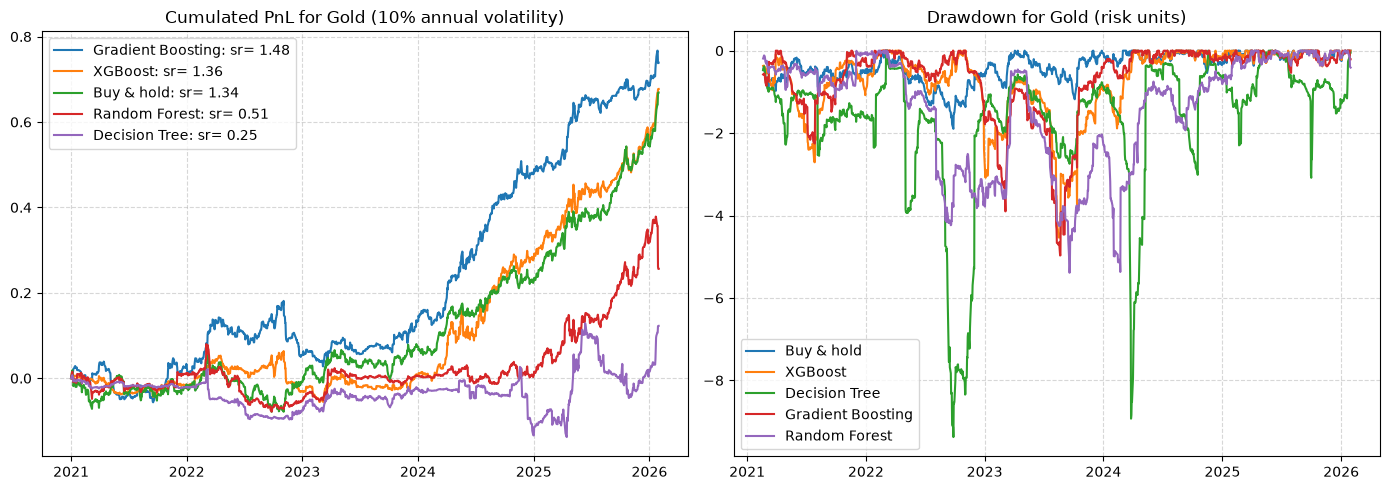

Forecast performance


,R2 vs zero,R2 vs hist. mean
Decision Tree,-0.0167,-0.0216
Random Forest,0.0007,-0.0041
Gradient Boosting,0.0009,-0.0039
XGBoost,0.0086,0.0039


Trading performance, without transaction costs


,Cumulated PnL (10% vol),Sharpe,Max drawdown
Decision Tree,0.12,0.25,-9.38
Random Forest,0.26,0.51,-5.39
Gradient Boosting,0.74,1.48,-4.97
XGBoost,0.68,1.36,-4.54
Buy & hold,0.67,1.34,-1.90


Sharpe ratio per year


,2021,2022,2023,2024,2025,2026
Decision Tree,-0.85,-0.79,0.97,-1.04,0.87,9.31
Random Forest,0.17,-0.75,1.05,0.03,2.17,-2.16
Gradient Boosting,0.45,0.19,1.02,3.01,1.85,3.93
XGBoost,-0.30,-0.20,0.63,2.03,2.03,10.50
Buy & hold,-0.16,0.07,1.01,1.66,2.48,10.65


In [ ]:
bt_gold = display_results(features=features_gold, target=target_gold, ret=ret_gold, best_models=best_models_gold,
                          best_windows=best_windows_gold, asset="Gold")

**Forecasts.** The $R^2$ values are tiny, between -2.2% and +0.9%. Only XGBoost beats the historical mean (+0.39%). This is normal for daily returns, and it should be compared with the $R^2$ of 83% implied by the paper.

**Trading.** Gradient Boosting (Sharpe = **1.48**) and XGBoost (**1.36**) are close to simply holding gold (**1.34**), and their cumulated PnL at equal volatility (0.74 and 0.68) is close to buy & hold (0.67). Several points call for caution:
- **The model chosen in advance is disappointing.** The Random Forest has a Sharpe of 0.51. Presenting Gradient Boosting as "the" result would be choosing the winner after seeing the test period.
- **The period matters.** Gold went up strongly from 2024. Sharpe ratios by year show that much of the performance comes from then: for Gradient Boosting, 0.45, 0.19 and 1.02 in 2021–2023, then 3.01 and 1.85. The 2026 column only covers one month and should not be interpreted.
- **Drawdowns are deeper than buy & hold.** The largest drawdown is -4.97 for Gradient Boosting and -4.54 for XGBoost, against -1.90 for buy & hold, in units of volatility.

### 4.2.2 Extension: oil

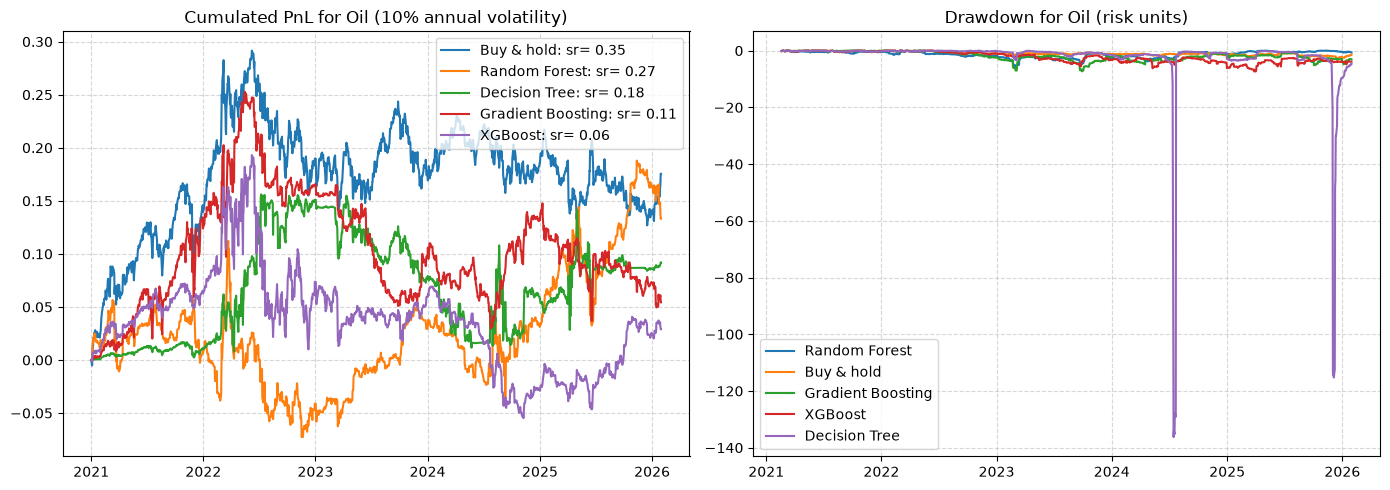

Forecast performance


,R2 vs zero,R2 vs hist. mean
Decision Tree,-0.0171,-0.0173
Random Forest,-0.0115,-0.0117
Gradient Boosting,-0.0096,-0.0098
XGBoost,-0.0006,-0.0008


Trading performance, without transaction costs


,Cumulated PnL (10% vol),Sharpe,Max drawdown
Decision Tree,0.09,0.18,-136.26
Random Forest,0.13,0.27,-5.78
Gradient Boosting,0.05,0.11,-7.29
XGBoost,0.03,0.06,-7.34
Buy & hold,0.18,0.35,-2.63


Sharpe ratio per year


,2021,2022,2023,2024,2025,2026
Decision Tree,0.65,1.13,-1.16,-0.15,0.23,4.85
Random Forest,0.08,-0.36,1.37,0.02,1.12,-3.54
Gradient Boosting,1.15,0.28,-1.19,0.50,-0.63,-2.70
XGBoost,1.51,0.06,-0.22,-1.57,1.02,1.42
Buy & hold,1.43,0.38,-0.17,0.15,-0.55,4.85


In [ ]:
bt_oil = display_results(features=features_oil, target=target_oil, ret=ret_oil, best_models=best_models_oil,
                         best_windows=best_windows_oil, asset="Oil")

All four models have a negative $R^2$ against both naive forecasts. All Sharpe ratios (**0.06 to 0.27**) are below buy & hold (**0.35**). The cumulated PnL is also lower for all four models, and their drawdowns are deeper. **The results on gold do not extend to oil.**

We cannot conclude from this that predictability is a specific property of gold, because the evidence on gold is itself weak.

*A note on the drawdown:* the very large value of the Decision Tree is an artefact. The drawdown is divided by a 36-day volatility, and this volatility is close to zero when a shallow tree takes tiny positions for some time.

## 4.3 H2: adding the positions of traders

**H2:** *adding the net positions of hedge funds and of the other groups of the CFTC Commitments of Traders report improves out-of-sample predictions.*

**The added variables** (11 in total) are all dated when they can be used:
- the net position of each of the 5 groups, as a share of open interest;
- the change of the Managed Money net position over 1 and 4 weeks, and of the Swap Dealers over 1 week;
- the Managed Money net position relative to its past year (z-score over 52 weeks);
- the weekly change of open interest.

**Protocol.** To isolate the effect of these variables, we keep everything else **identical**: same dates, same hyper-parameters, same training windows. We compare with and without CoT data for two feature sets:
- *full*: the 230 baseline features. The 11 new variables can get lost among them;
- *compact*: lags and moving averages of the target and the VIX dummy (20 features). The new variables have a better chance of being picked up.

**Metrics.** We compare the $R^2$ against a zero forecast and the Sharpe ratio, with and without CoT data, over the 16 combinations of asset, feature set and model.

In [ ]:
def compact_columns(features: pd.DataFrame, target_col: str) -> list[str]:
    return [c for c in features.columns if c.startswith(f"{target_col}_") or c == "vix_dummy"]

def compare_with_cot(features, target, ret, best_models, best_windows, asset):

    cot_features = build_cot_features(cot, asset, features.index).dropna()
    common = cot_features.index
    specs = {"full": features.columns.to_list(), "compact": compact_columns(features, asset)}

    rows, curves = [], {}
    for spec, columns in specs.items():
        X_without = features.loc[common, columns]
        X_with = X_without.join(cot_features)
        y = target.reindex(common)

        for name, model in best_models.items():
            without = run_backtest(X_without, y, ret, model, best_windows[name])
            with_cot = run_backtest(X_with, y, ret, model, best_windows[name])

            rows.append({
                "asset": asset, "features": spec, "model": name,
                "R2 without": forecast_metrics(without, y, ret)["R2 vs zero"],
                "R2 with CoT": forecast_metrics(with_cot, y, ret)["R2 vs zero"],
                "Sharpe without": sharpe_ratio(without.pnl_),
                "Sharpe with CoT": sharpe_ratio(with_cot.pnl_),
            })
            curves[(spec, name)] = (without.pnl_, with_cot.pnl_)

    return pd.DataFrame(rows), curves

In [ ]:
h2_gold, curves_gold = compare_with_cot(features_gold, target_gold, ret_gold, best_models_gold, best_windows_gold, "gold")
h2_oil, curves_oil = compare_with_cot(features_oil, target_oil, ret_oil, best_models_oil, best_windows_oil, "oil")

h2_table = pd.concat([h2_gold, h2_oil]).set_index(["asset", "features", "model"])
h2_table["R2 gain"] = h2_table["R2 with CoT"] - h2_table["R2 without"]
h2_table["Sharpe gain"] = h2_table["Sharpe with CoT"] - h2_table["Sharpe without"]

display(h2_table[["R2 without", "R2 with CoT", "R2 gain", "Sharpe without", "Sharpe with CoT", "Sharpe gain"]].round(4))

print("Models where the R2 improves:", int((h2_table["R2 gain"] > 0).sum()), "out of", len(h2_table))
print("Models where the Sharpe improves:", int((h2_table["Sharpe gain"] > 0).sum()), "out of", len(h2_table))

R2 without  R2 with CoT  R2 gain  \
asset features model                                                 
gold  full     Decision Tree         -0.0167      -0.0026   0.0141   
               Random Forest          0.0007       0.0014   0.0007   
               Gradient Boosting      0.0009       0.0007  -0.0002   
               XGBoost                0.0086       0.0079  -0.0006   
      compact  Decision Tree         -0.0156      -0.0222  -0.0066   
               Random Forest         -0.0123      -0.0081   0.0042   
               Gradient Boosting     -0.0115      -0.0075   0.0039   
               XGBoost                0.0010       0.0020   0.0010   
oil   full     Decision Tree         -0.0171      -0.0602  -0.0431   
               Random Forest         -0.0115      -0.0152  -0.0038   
               Gradient Boosting     -0.0096      -0.0094   0.0001   
               XGBoost               -0.0006      -0.0002   0.0005   
      compact  Decision Tree         -0.0085      -0.0096  -0.0011   
               Random Forest         -0.0122      -0.0120   0.0002   
               Gradient Boosting     -0.0012       0.0006   0.0019   
               XGBoost                0.0000       0.0016   0.0015   

                                  Sharpe without  Sharpe with CoT  Sharpe gain  
asset features model                                                            
gold  full     Decision Tree              0.2456           1.4276       1.1819  
               Random Forest              0.5126           0.6294       0.1168  
               Gradient Boosting          1.4799           1.4713      -0.0086  
               XGBoost                    1.3565           1.2881      -0.0683  
      compact  Decision Tree              0.2523           0.2152      -0.0371  
               Random Forest              0.0638           0.1906       0.1269  
               Gradient Boosting          0.6335           0.7750       0.1415  
               XGBoost                    0.8919           0.9051       0.0133  
oil   full     Decision Tree              0.1842          -0.4012      -0.5854  
               Random Forest              0.2667           0.1679      -0.0988  
               Gradient Boosting          0.1089           0.0987      -0.0102  
               XGBoost                    0.0582           0.1313       0.0731  
      compact  Decision Tree              0.7545           0.5984      -0.1561  
               Random Forest              0.4691           0.4371      -0.0320  
               Gradient Boosting          0.5003           0.6348       0.1345  
               XGBoost                    0.3352           0.4890       0.1537

Models where the R2 improves: 10 out of 16
Models where the Sharpe improves: 8 out of 16


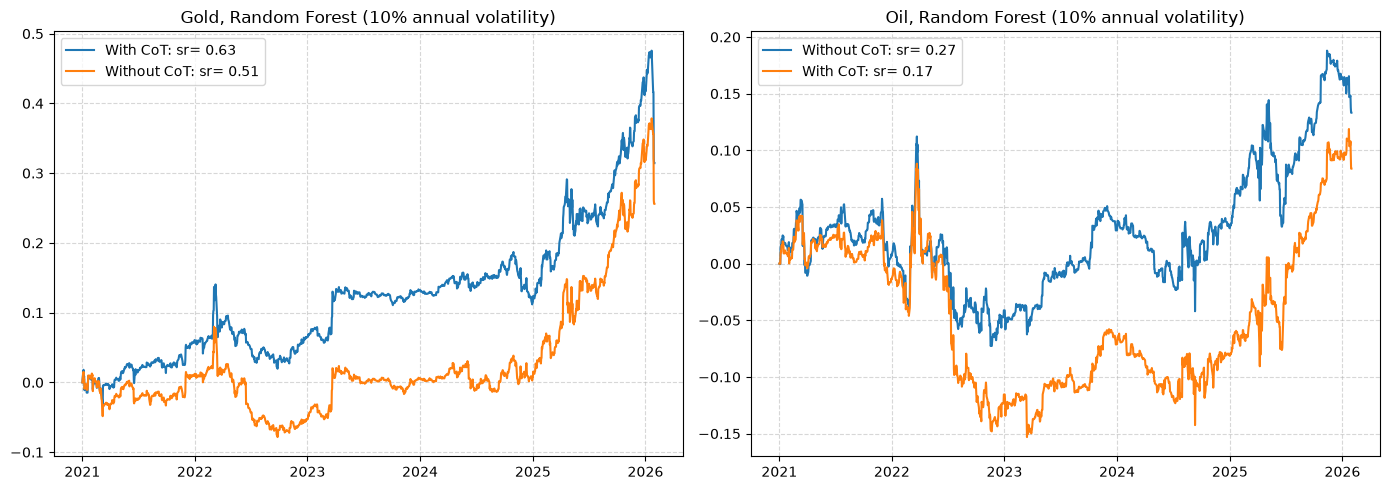

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, asset, curves, best in zip(axes, ["Gold", "Oil"], [curves_gold, curves_oil], [best_name_gold, best_name_oil]):
    without, with_cot = curves[("full", best)]
    line({"Without CoT": rescale(without), "With CoT": rescale(with_cot)}, cumsum=True, ax=ax, loc="best",
         title=f"{asset}, {best} (10% annual volatility)")

plt.tight_layout()
plt.show()

**H2 is not supported.**

- **Forecasts.** The $R^2$ improves in 10 comparisons out of 16, and the gains stay below 0.5 percentage point, with one exception: the single decision tree on gold (+1.4 points).
- **Trading.** The Sharpe ratio improves in 8 comparisons out of 16. For the two best gold models with all the features, it does not improve: Gradient Boosting goes from 1.48 to 1.47 and XGBoost from 1.36 to 1.29.
- **The largest change is not reliable.** The Sharpe of the gold decision tree goes from 0.25 to 1.43, but with the same variables the Sharpe of the oil decision tree goes from 0.18 to -0.40. A single tree is too unstable to support a conclusion.
- **A weak hint on compact models.** With few variables, the $R^2$ improves in 6 cases out of 8, and for oil the Sharpe of the two boosting models also rises (from 0.50 to 0.63 and from 0.34 to 0.49). The gains remain small, but this would be the natural direction for further work.

Two limits are worth keeping in mind. The data are weekly and we impose a conservative publication delay, so the information may already be priced when we can use it. We also keep the hyper-parameters tuned without CoT data, to isolate its effect, so this does not exclude that a model built specifically around these variables would do better.

## 4.4 Robustness tests

We test whether our main findings survive **algorithmic modifications**: another way of dating the data, a smaller feature set chosen by two different selection methods, a different training-window length, and different random seeds.

### 4.4.1 Sensitivity to the dating of the features

We compare three conventions for the best model of each asset:
- `async`: our baseline, which respects closing times;
- `gap`: every series waits one more day, so the position is decided after all markets have closed;
- `naive`: every return dated *t* is used at *t*, which ignores that US markets close after the settlement of gold.

In [ ]:
def timing_sensitivity(target_col, model, window):
    rows = {}
    for timing in ["async", "gap", "naive"]:
        X, y, ret = build_features(cleaned_data, lag_order=10, target_col=target_col, timing=timing)
        bt = run_backtest(X, y, ret, model, window)
        rows[timing] = {**forecast_metrics(bt, y, ret), "Sharpe": sharpe_ratio(bt.pnl_)}
    return pd.DataFrame(rows).T.round(4)

print("Gold,", best_name_gold)
display(timing_sensitivity("gold", best_models_gold[best_name_gold], best_windows_gold[best_name_gold]))
print("Oil,", best_name_oil)
display(timing_sensitivity("oil", best_models_oil[best_name_oil], best_windows_oil[best_name_oil]))

Gold, Random Forest


,R2 vs zero,R2 vs hist. mean,Sharpe
async,0.0007,-0.0041,0.5126
gap,0.0037,-0.0010,0.8451
naive,0.0021,-0.0027,0.6548


Oil, Random Forest


,R2 vs zero,R2 vs hist. mean,Sharpe
async,-0.0115,-0.0117,0.2667
gap,-0.0108,-0.0110,0.4761
naive,-0.0092,-0.0094,0.4625


The conclusions do not depend on this choice. The Sharpe ratio of the Random Forest goes from 0.51 to 0.85 for gold and from 0.27 to 0.48 for oil, and the $R^2$ values remain within a few tenths of a percent. Such gaps are comparable to what changing the seed or the window can produce (see below), so we should not over-interpret the ranking: in particular, the `naive` convention does not produce an obvious gain here. We keep `async` because it is the one that respects the information really available.

### 4.4.2 Feature selection

In [ ]:
def selection_summary(features, target, ret, best_models, best_windows, selected: dict) -> pd.DataFrame:
    rows = {}
    for spec, columns in selected.items():
        for name, model in best_models.items():
            bt = run_backtest(features[columns], target, ret, model, best_windows[name])
            rows[(spec, name)] = {"n features": len(columns), **forecast_metrics(bt, target, ret), "Sharpe": sharpe_ratio(bt.pnl_)}
    return pd.DataFrame(rows).T.round(4)

selected_gold = {
    "all": features_gold.columns.to_list(),
    "RF permutation": features_selector_rf(best_models_gold["Random Forest"], X_tune_gold, y_tune_gold, n_features=25),
    "LASSO": features_selector_lasso(X_tune_gold, y_tune_gold),
}
selected_oil = {
    "all": features_oil.columns.to_list(),
    "RF permutation": features_selector_rf(best_models_oil["Random Forest"], X_tune_oil, y_tune_oil, n_features=25),
    "LASSO": features_selector_lasso(X_tune_oil, y_tune_oil),
}
selected_gold = {k: v for k, v in selected_gold.items() if len(v) > 0}
selected_oil = {k: v for k, v in selected_oil.items() if len(v) > 0}
print("Selected by LASSO. Gold:", len(selected_gold.get("LASSO", [])), "| Oil:", len(selected_oil.get("LASSO", [])))

print("Gold")
display(selection_summary(features_gold, target_gold, ret_gold, best_models_gold, best_windows_gold, selected_gold))
print("Oil")
display(selection_summary(features_oil, target_oil, ret_oil, best_models_oil, best_windows_oil, selected_oil))

Selected by LASSO. Gold: 0 | Oil: 0
Gold


n features  R2 vs zero  R2 vs hist. mean  \
all            Decision Tree           230.0     -0.0167           -0.0216   
               Random Forest           230.0      0.0007           -0.0041   
               Gradient Boosting       230.0      0.0009           -0.0039   
               XGBoost                 230.0      0.0086            0.0039   
RF permutation Decision Tree            25.0     -0.0131           -0.0179   
               Random Forest            25.0      0.0018           -0.0029   
               Gradient Boosting        25.0     -0.0007           -0.0054   
               XGBoost                  25.0      0.0059            0.0012   

                                  Sharpe  
all            Decision Tree      0.2456  
               Random Forest      0.5126  
               Gradient Boosting  1.4799  
               XGBoost            1.3565  
RF permutation Decision Tree      0.6044  
               Random Forest      0.7647  
               Gradient Boosting  1.0345  
               XGBoost            1.1309

Oil


n features  R2 vs zero  R2 vs hist. mean  \
all            Decision Tree           230.0     -0.0171           -0.0173   
               Random Forest           230.0     -0.0115           -0.0117   
               Gradient Boosting       230.0     -0.0096           -0.0098   
               XGBoost                 230.0     -0.0006           -0.0008   
RF permutation Decision Tree            25.0     -0.0514           -0.0517   
               Random Forest            25.0     -0.0176           -0.0178   
               Gradient Boosting        25.0     -0.0126           -0.0128   
               XGBoost                  25.0      0.0028            0.0026   

                                  Sharpe  
all            Decision Tree      0.1842  
               Random Forest      0.2667  
               Gradient Boosting  0.1089  
               XGBoost            0.0582  
RF permutation Decision Tree      0.6575  
               Random Forest     -0.0653  
               Gradient Boosting -0.1292  
               XGBoost            0.3432

**LASSO selects no variable at all**, for either asset. With a cross-validation that respects time, the best penalty sets all coefficients to zero, which again means that no linear combination of the predictors beats a constant forecast. The LASSO results therefore reduce to the row using all the features.

**With the 25 variables of the permutation importance:**
- on **gold**, the two boosting models remain above a Sharpe of 1 (1.03 and 1.13), although now below buy & hold (1.34), so the positive PnL is reasonably stable with respect to the features;
- on **oil**, Sharpe ratios change sign depending on the model (from -0.13 to 0.66), and only XGBoost has a positive $R^2$. Nothing consistent emerges.

### 4.4.3 Sensitivity to the length of the training window

The baseline window is chosen during tuning. We now vary it for the selected model of each asset and, for gold, for the two boosting models that give the best results in section 4.2.1. This checks that the results are not tied to one particular choice.

In [ ]:
def window_sensitivity(features, target, ret, model, windows=(60, 120, 250, 500, 1000, 2000)):
    rows = {}
    for w in windows:
        bt = run_backtest(features, target, ret, model, w)
        rows[w] = {"R2 vs zero": forecast_metrics(bt, target, ret)["R2 vs zero"], "Sharpe": sharpe_ratio(bt.pnl_)}
    return pd.DataFrame(rows).T.rename_axis("train window (days)").round(3)

print("Gold,", best_name_gold)
display(window_sensitivity(features_gold, target_gold, ret_gold, best_models_gold[best_name_gold]))
print("Gold, Gradient Boosting")
display(window_sensitivity(features_gold, target_gold, ret_gold, best_models_gold["Gradient Boosting"]))
print("Gold, XGBoost")
display(window_sensitivity(features_gold, target_gold, ret_gold, best_models_gold["XGBoost"]))
print("Oil,", best_name_oil)
display(window_sensitivity(features_oil, target_oil, ret_oil, best_models_oil[best_name_oil]))

Gold, Random Forest


,R2 vs zero,Sharpe
train window (days),,
60,-0.005,0.773
120,0.000,0.848
250,0.002,0.902
500,0.005,0.933
1000,0.001,0.513
2000,0.000,0.375


Gold, Gradient Boosting


,R2 vs zero,Sharpe
train window (days),,
60,-0.014,1.304
120,0.001,1.480
250,0.004,1.117
500,0.007,1.300
1000,0.004,0.936
2000,0.001,0.675


Gold, XGBoost


,R2 vs zero,Sharpe
train window (days),,
60,0.001,0.853
120,0.009,1.356
250,0.011,1.542
500,0.007,1.223
1000,0.003,0.923
2000,0.004,0.971


Oil, Random Forest


,R2 vs zero,Sharpe
train window (days),,
60,-0.011,-0.329
120,-0.016,-0.202
250,-0.009,0.059
500,-0.010,0.422
1000,-0.011,0.267
2000,-0.017,-0.431


This table is very instructive for gold:
- The Sharpe ratio changes a lot with the window: from 0.68 to 1.48 for Gradient Boosting, from 0.85 to 1.54 for XGBoost and from 0.38 to 0.93 for the Random Forest.
- **The advantage over buy & hold depends on this choice.** Only 3 of the 12 windows tested for the two boosting models exceed the 1.34 of buy & hold: 120 days for Gradient Boosting, 120 and 250 days for XGBoost.

For oil, the Sharpe ratio changes sign with the window (from -0.43 to 0.42), which confirms the absence of a robust signal.

The windows chosen in the tuning were not the ones with the best test results for every model, which is expected: picking the best row of this table afterwards would be data snooping.

### 4.4.4 Sensitivity to the random seed

Random forests and subsampled boosting depend on a random seed. We re-estimate the best models with 5 seeds.

In [ ]:
def seed_sensitivity(features, target, ret, best_models, best_windows, seeds=(1, 2, 3, 4, 5)):
    rows = {}
    for name, model in best_models.items():
        sharpes = [
            sharpe_ratio(run_backtest(features, target, ret, clone(model).set_params(random_state=s), best_windows[name]).pnl_)
            for s in seeds
        ]
        rows[name] = {"mean": np.mean(sharpes), "min": np.min(sharpes), "max": np.max(sharpes)}
    return pd.DataFrame(rows).T.round(2)

print("Sharpe ratio across seeds, gold")
display(seed_sensitivity(features_gold, target_gold, ret_gold, best_models_gold, best_windows_gold))
print("Sharpe ratio across seeds, oil")
display(seed_sensitivity(features_oil, target_oil, ret_oil, best_models_oil, best_windows_oil))

Sharpe ratio across seeds, gold


,mean,min,max
Decision Tree,0.65,-0.12,1.25
Random Forest,0.57,0.45,0.76
Gradient Boosting,1.48,1.48,1.48
XGBoost,1.36,1.33,1.44


Sharpe ratio across seeds, oil


,mean,min,max
Decision Tree,0.09,-0.15,0.44
Random Forest,0.27,0.14,0.44
Gradient Boosting,0.11,0.11,0.11
XGBoost,0.21,0.09,0.37


The variability is far from negligible. On gold, the Sharpe ratio goes from -0.12 to 1.25 for the Decision Tree and from 0.45 to 0.76 for the Random Forest, while XGBoost is more stable (1.33 to 1.44). The selected Gradient Boosting configuration uses no subsampling, which explains why its results do not depend on the seed. Differences between models of a few tenths of Sharpe should therefore not be over-interpreted.

### 4.4.5 Summary of the robustness results

- **Gold, boosting models:** the Sharpe ratio stays around or above 1 with reduced features and with most windows, so the positive PnL is stable. However, the advantage over buy & hold is not.
- **Gold, other models:** the Random Forest and the Decision Tree are weaker and less stable, so the conclusion does not hold for tree-based models in general.
- **Oil:** results change sign depending on the features, the window and the model, with no consistent winner.
- **Dating of the features:** changing the convention does not change the conclusions.
- **LASSO:** no variable is selected, which confirms that the linear signal is extremely weak.

# 5. Conclusion

**Main findings.**

- **H1 is rejected.** Rebuilt from open data with a correct dating of the predictors, the design of Cohen & Aiche (2023) does not beat the mean (relative error above 1, against 0.17). We recover the paper's numbers when the moving averages contain the return being predicted, which is consistent with a look-ahead bias, without being a proof.
- **Gold.** In a true walk-forward forecast, predictability is very small ($R^2$ below 1%). Boosting models reach Sharpe ratios of 1.36 to 1.48, similar to the 1.34 of buy & hold, and their advantage depends on the training window.
- **Oil.** The results do not extend to crude oil: $R^2$ values are negative, and no strategy beats buy & hold.
- **H2 is not supported.** CFTC positions bring no consistent improvement in forecasts or in Sharpe ratios.

**What this means in practice.** A very high accuracy on daily returns should first raise a question about the design of the experiment. And a good Sharpe ratio means little without a benchmark: over a period when gold rose sharply, simply holding it already gave a Sharpe of 1.34.

**Limitations of our work.**
- Only one test period is available, and it is dominated by the 2024–2025 gold rally.
- We do not run formal statistical tests. Our conclusions rest on the size of the differences and on their stability across models, features, windows and seeds.
- **Transaction costs and slippage are not modelled**; with daily rebalancing they would reduce the PnL and the Sharpe ratio of the strategies, unlike buy & hold.
- The replication is imperfect: MOEX and SET are missing, and some hyper-parameters of the paper are assumed.
- Closing times are approximate, and we assume that the Yahoo Finance close of a futures contract corresponds to its settlement.
- Continuous futures from Yahoo Finance include jumps when the contract rolls, which we do not adjust.
- The positions given by `TimingMeanVariance` imply a high leverage, so PnL levels are not realistic returns.
- Our validation cannot truly separate the models, because their errors are nearly identical.

**Further work.** Test models built specifically around positioning data at a weekly horizon, where CFTC data is less stale, and evaluate them on other commodities.

# References

1. Cohen, G. & Aiche, A. (2023). Forecasting gold price using machine learning methodologies. *Chaos, Solitons & Fractals*, 175, 114079. https://doi.org/10.1016/j.chaos.2023.114079
2. Bosch, D. & Pradkhan, E. (2015). The impact of speculation on precious metals futures markets. *Resources Policy*, 44, 118-134.
3. Champonnois, S. `skfin`. https://github.com/schampon/skfin
4. CFTC, Commitments of Traders, disaggregated reports. https://www.cftc.gov/MarketReports/CommitmentsofTraders/index.htm